# Milestone M3 · Ablasi, Perbandingan Utama (3 Seed), Korelasi mAP–Galat Hitung, Efisiensi, Analisis Kesalahan & EigenCAM (Topik T1-A)
**Deep Learning A · Tugas Besar Pengganti UAS**
Tsabita Shafa Aurellia (`240441100052`) · Putri Eka Safira (`240441100087`)

**Pertanyaan riset (Daftar Topik T1-A):** seberapa kuat korelasi antara mAP@[0.5:0.95] dan galat hitung sel per citra
(MAE/MAPE per kelas) pada detektor one-stage (YOLOv8s) dan two-stage (Faster R-CNN ResNet-50-FPN)?

**Hipotesis (dari proposal M1, ditetapkan sebelum hasil terlihat)**
- **H1** · korelasi Spearman antar run antara mAP@[.5:.95] dan MAE hitung RBC lemah (|ρ| < 0,5).
- **H2** · mengubah ambang IoU NMS 0,45 → 0,75 menggeser MAE RBC < 0,1 sel/citra (NMS bukan penyebab dominan; audit M2: hanya 0,29% RBC bertumpuk IoU > 0,5).
- **H3** · resolusi 640 → 832 px menurunkan MAE platelet YOLOv8s ≥ 10%, dan MAPE platelet tertinggi di kedua model.

**Titik awal:** baseline M2 sudah selesai — R01 YOLOv8s (val mAP@[.5:.95] 0,841; MAE RBC 1,14) dan R02 Faster R-CNN
(0,835; MAE RBC 0,67). Notebook ini melanjutkan dari bobot dan log di Google Drive.

### Isi notebook
| No | Bagian | Pemilik | GPU |
|---|---|---|---|
| 0 | Setup & panel kendali sesi | — | — |
| 1 | Persiapan: split tetap, anotasi COCO, cek ulang kebocoran latih–uji | Putri | tidak |
| 2.1 | Ablasi A1 (menu): resolusi YOLOv8s 640 vs 832 → **R04** | Tsabita | T4 ± 25 menit |
| 2.2 | Ablasi A2 (menu): ambang IoU NMS 0,45 / 0,60 / 0,75 pada R01 & R02, **tanpa latih ulang** | Putri | T4 ± 10 menit |
| 2.3 | Strategi fine-tuning (menu): Faster R-CNN backbone beku → **R06** | Putri | T4 ± 20 menit |
| 2.4 | Tabel & grafik semua ablasi di validasi | Tsabita | tidak |
| 3.1 | YOLOv8s terbaik + seed 123 & 2024 → **R07, R08** | Tsabita | T4 ± 35 menit |
| 3.2 | Faster R-CNN terbaik + seed 123 & 2024 → **R09, R10** | Putri | T4 ± 50 menit |
| 3.3 | Korelasi Pearson/Spearman mAP vs MAE antar run (validasi) | Tsabita | tidak |
| 3.4 | Set uji dibuka **sekali**: tabel utama rerata ± SD, uji statistik berpasangan, per ukuran objek, kepadatan & sumber | Putri | T4 singkat |
| 4 | Efisiensi: parameter & latensi batch 1 (K7) | Tsabita | T4 singkat |
| 5.1 | Analisis kesalahan berkategori + galeri (K6) | Putri | tidak |
| 5.2 | Interpretabilitas EigenCAM, 4 benar + 4 salah per model (K6) | Tsabita | T4 singkat |
| 6 | Ringkasan: kurva pelatihan, jawaban H1–H3, total jam GPU, arsip zip | Bersama | tidak |

Bagian dikerjakan **selang-seling** Tsabita ↔ Putri; hanya ringkasan 6 yang bersama.




## 0. Setup & panel kendali
### 0.1 Hubungkan Drive, temukan folder proyek, unduh dataset, pasang paket

In [1]:
# === Setup: jalankan sel ini pertama kali ===
import os, sys, subprocess

PIP_PAKET = ['ultralytics', 'pycocotools']   # hanya paket yang belum ada di Colab; torch/torchvision TIDAK dipasang ulang

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Cari folder proyek di Drive secara otomatis (folder yang berisi src/pipeline.py dan notebooks/),
    # termasuk folder yang dibagikan lewat shortcut. Nama folder tidak harus persis sama.
    import glob
    kandidat = [os.path.dirname(os.path.dirname(p)) for pola in
                ["/content/drive/MyDrive/src/pipeline.py",
                 "/content/drive/MyDrive/*/src/pipeline.py",
                 "/content/drive/MyDrive/*/*/src/pipeline.py",
                 "/content/drive/MyDrive/*/*/*/src/pipeline.py"]
                for p in glob.glob(pola)]
    kandidat = [k for k in kandidat if os.path.isdir(os.path.join(k, "notebooks"))]
    assert kandidat, "Folder proyek tidak ditemukan di Google Drive. Unggah folder hasil ekstrak zip ke My Drive."
    VERSI = "HEMAT-2026-11-23"   # hanya folder dengan berkas VERSION persis ini yang dipakai (folder lama diabaikan)
    def _versi(k):
        f = os.path.join(k, "VERSION")
        return open(f).read().strip() if os.path.exists(f) else "-"
    semua = sorted(set(os.path.realpath(k) for k in kandidat))
    kandidat = [k for k in semua if _versi(k) == VERSI]
    print("Folder proyek di Drive:")
    for k in semua:
        print(f"  {'→ DIPAKAI ' if kandidat and k == kandidat[0] else '  diabaikan'} {k}  (VERSION: {_versi(k)})")
    assert kandidat, (f"Folder versi {VERSI} tidak ditemukan. Ekstrak zip UAS-DL-T1A-TXL-PBC_HEMAT lalu unggah foldernya ke My Drive "
                      "(akun Putri: Add shortcut ke folder milik Tsabita).")
    assert len(kandidat) == 1, "Ada lebih dari satu folder versi ini di Drive; sisakan satu (hapus/ganti nama yang lain)."
    PROJECT = kandidat[0]
    os.chdir(PROJECT)
    if not os.path.isdir("/content/TXL-PBC_Dataset/TXL-PBC"):  # dataset diunduh ke disk lokal Colab (lebih cepat)
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/lugan113/TXL-PBC_Dataset", "/content/TXL-PBC_Dataset"], check=True)
    if PIP_PAKET:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PIP_PAKET],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print(r.stdout[-2000:], r.stderr[-3000:])
            raise RuntimeError("pip install gagal; salin pesan di atas untuk diperiksa")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from src.paths import *
DATA_ROOT = find_data_root()
print("Proyek :", os.getcwd())
print("Dataset:", DATA_ROOT)
print("Python :", sys.version.split()[0])

Mounted at /content/drive
Folder proyek di Drive:
  → DIPAKAI  /content/drive/MyDrive/Colab Notebooks/UAS  (VERSION: HEMAT-2026-11-23)
Proyek : /content/drive/MyDrive/Colab Notebooks/UAS
Dataset: /content/TXL-PBC_Dataset/TXL-PBC
Python : 3.13.16


### 0.2 Pengaturan sesi & daftar pekerjaan
Biasanya tidak perlu diubah. Sel ini menampilkan log eksperimen dan daftar pekerjaan yang **belum selesai**.

In [2]:
# ======================== PENGATURAN SESI ========================
PELAKSANA = "semua"     # "semua" (bawaan), "Tsabita", atau "Putri" → hanya pekerjaan milik orang itu yang dijalankan
# =================================================================
OWNER = {"R04": "Tsabita", "R07": "Tsabita", "R08": "Tsabita", "R06": "Putri", "R09": "Putri", "R10": "Putri",
         "NMS": "Putri", "UJI": "Putri", "EFISIENSI": "Tsabita", "XAI": "Tsabita"}

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # kurangi fragmentasi VRAM
import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.viz import style, label_bars, BAR, CLASS_COLORS, MODEL_COLORS, SOURCE_COLORS, INK_2
from src.exp_log import read_log, load_config
from src.evaluate import load_json
from src import pipeline as P
from src.summary import label, model_of, eval_runs, mean_sd, per_image_errors, runs_done, correlation_table

style()
pd.set_option("display.max_columns", None); pd.set_option("display.width", 2000)
RUNS_DIR = PROJECT_ROOT / "runs"
EVAL_DIR = OUTPUT_DIR / "eval"; EVAL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TEST_MARKER = EVAL_DIR / "SET_UJI_DIBUKA.txt"
COLS = (["mAP50", "mAP50_95", "AP_small", "AP_medium", "AP_large"] + [f"AP50_95_{c}" for c in CLASSES]
        + [f"MAE_{c}" for c in CLASSES] + [f"MAPE_{c}" for c in CLASSES])

import time
try:
    import torch
    GPU_OK = torch.cuda.is_available()
except ImportError:
    GPU_OK = False
if GPU_OK:
    free, total = torch.cuda.mem_get_info()
    print(f"GPU {torch.cuda.get_device_name(0)} · VRAM {total / 1024**3:.1f} GB, bebas {free / 1024**3:.1f} GB · torch {torch.__version__}")
else:
    print("PERINGATAN: GPU tidak aktif. Pekerjaan yang butuh GPU akan dilewati; pilih Runtime > Change runtime type > T4 GPU.")
T_SESI = time.perf_counter()

def boleh(tugas):
    """Pekerjaan boleh dijalankan di sesi ini bila GPU aktif dan sesuai PELAKSANA."""
    return GPU_OK and PELAKSANA in ("semua", OWNER[tugas])

def status(run_id):
    log = read_log().set_index("run_id")
    return log.loc[run_id, "status"] if run_id in log.index else "planned"

def jalankan(run_id, idx=None, total=None):
    """Seperti referensi: lewati bila sudah selesai, selain itu latih + evaluasi validasi dan cetak progres."""
    tag = f"[{idx}/{total}] " if idx else ""
    if status(run_id) == "done":
        print(f"{tag}SKIP (sudah selesai): {run_id} · {label(run_id)}")
        return
    if not boleh(run_id):
        alasan = "GPU tidak aktif" if not GPU_OK else f"milik {OWNER[run_id]} (PELAKSANA = {PELAKSANA!r})"
        print(f"{tag}TUNDA: {run_id} · {alasan}")
        return
    t0 = time.perf_counter()
    print(f"{tag}MULAI {run_id} · {label(run_id)} · VRAM terpakai sebelum: {P.gpu_used_gb():.2f} GB")
    m = P.run_isolated(run_id, DATA_ROOT)           # proses terpisah → VRAM & RAM dilepas penuh setelah selesai
    print(f"{tag}{run_id} | val mAP50-95={m['mAP50_95']:.4f} | MAE RBC={m['MAE_RBC']:.3f} | MAE platelet={m['MAE_Platelets']:.3f} "
          f"({(time.perf_counter() - t0) / 60:.1f} mnt, total sesi {(time.perf_counter() - T_SESI) / 60:.1f} mnt) "
          f"· VRAM terpakai sesudah: {P.gpu_used_gb():.2f} GB")

# Pemulihan otomatis: bila log.csv kosong/kurang padahal hasil run (runs/ & outputs/preds/) ada di Drive
from src.paths import PRED_DIR
_log = read_log()
_done = set(_log.run_id[_log.status == "done"]) if len(_log) else set()
_pred = {p.name[:-len("_val.json")] for p in PRED_DIR.glob("*_val.json")}
_latih = {p.name for p in RUNS_DIR.glob("R*") if p.is_dir()}
if (_pred - _done) or (_latih - set(_log.run_id if len(_log) else [])):
    print("Log tidak lengkap -> dipulihkan dari runs/ dan outputs/preds/ (tanpa latih ulang):")
    P.rebuild_log(DATA_ROOT, RUNS_DIR)
log0 = read_log()
belum = log0[log0.status != "done"]
print(f"\n=== Log eksperimen: {(log0.status == 'done').sum()} selesai, {len(belum)} belum ===")
display(log0[log0.status == "done"][["run_id", "owner", "factor", "value", "seed", "gpu_minutes", "val_mAP50_95", "val_MAE_RBC"]].fillna("–"))
if len(belum):
    print("Pekerjaan yang akan dijalankan/dilanjutkan notebook ini:", ", ".join(belum.run_id))

GPU Tesla T4 · VRAM 14.6 GB, bebas 14.5 GB · torch 2.14.1+cu130

=== Log eksperimen: 2 selesai, 0 belum ===


,run_id,owner,factor,value,seed,gpu_minutes,val_mAP50_95,val_MAE_RBC
0,R01,Tsabita,baseline,imgsz 640,42,17.7,0.8478,0.960
1,R02,Putri,baseline,"anchor default, fine-tune penuh",42,25.4,0.8242,0.679


## 1. Persiapan: split tetap, anotasi COCO & cek ulang kebocoran — Putri
**Tujuan:** memastikan notebook M3 memakai data yang **sama persis** dengan M2 sebelum eksperimen dilanjutkan.
- Split resmi TXL-PBC dibaca dari `splits/{train,val,test}.txt` (seed 42) dan dicocokkan jumlahnya.
- Anotasi COCO (`outputs/coco/`) dibuat ulang bila belum ada; label duplikat dibuang seperti di M2.
- Kebocoran latih–uji diperiksa ulang dengan MD5 (identik) dan pHash (Hamming ≤ 8), seperti di referensi.

**Keluaran:** ringkasan di layar; hasil M2 lengkap ada di `outputs/leakage/`.

In [3]:
from src.data_utils import read_split_file
from src.leakage import hash_split, cross_pairs

sizes = {s: len(read_split_file(s)) for s in SPLITS}
print("Split tetap (split resmi, seed 42):", sizes)
assert sizes == {"train": 882, "val": 252, "test": 126}, "Split tidak sama dengan M2"

P.ensure_coco(DATA_ROOT)
for s in SPLITS:
    g = load_json(COCO_DIR / f"{s}.json")
    n = pd.Series([a["category_id"] for a in g["annotations"]]).value_counts().sort_index()
    print(f"COCO {s:5s}: {len(g['images'])} citra · {len(g['annotations'])} kotak · "
          + " · ".join(f"{c} {n.get(i + 1, 0)}" for i, c in enumerate(CLASSES)))

H_tr = hash_split(DATA_ROOT, "train", read_split_file("train"))
H_te = hash_split(DATA_ROOT, "test", read_split_file("test"))
same_md5 = len(set(H_tr.md5) & set(H_te.md5))
near = cross_pairs(H_tr, H_te, max_dist=8)
print(f"\nCek kebocoran latih–uji -> MD5 identik: {same_md5} | pHash Hamming ≤ 8: {len(near)}")
print("Siap menjalankan eksperimen M3.")

Split tetap (split resmi, seed 42): {'train': 882, 'val': 252, 'test': 126}
COCO train: 882 citra · 12491 kotak · WBC 903 · RBC 11206 · Platelets 382
COCO val  : 252 citra · 3737 kotak · WBC 257 · RBC 3368 · Platelets 112
COCO test : 126 citra · 1868 kotak · WBC 131 · RBC 1688 · Platelets 49

Cek kebocoran latih–uji -> MD5 identik: 0 | pHash Hamming ≤ 8: 0
Siap menjalankan eksperimen M3.


## 2. Studi ablasi satu-faktor (seed 42)
Setiap anggota memiliki satu ablasi dari **menu T1-A**; tiap perbandingan hanya mengubah **satu faktor** terhadap
baseline M2. Ablasi dijalankan **sebelum** perbandingan utama karena hasilnya menentukan konfigurasi terbaik yang
diulang dengan 3 seed (pemilihan hanya memakai set validasi).

### 2.1 Ablasi A1 · resolusi masukan YOLOv8s 640 vs 832 — Tsabita
| | |
|---|---|
| **Faktor yang diubah** | `imgsz` 640 (R01) → 832 (R04); semua pengaturan lain diwarisi `configs/R01.yaml` |
| **Alasan** | 43,6% platelet < 32² px; resolusi lebih tinggi memperbesar platelet di peta fitur |
| **Menguji** | H3 (MAE platelet turun ≥ 10%) |
| **Dijalankan** | otomatis bila belum selesai (pemilik: Tsabita) |
| **Keluaran** | `runs/R04/` (bobot), `outputs/preds/R04_val.json`, baris R04 di `experiments/log.csv` |

In [4]:
jalankan("R04", 1, 2)

[1/2] MULAI R04 · YOLOv8s · 832 · NMS 0,70 · VRAM terpakai sebelum: 0.10 GB
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_txl.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_

### 2.2 Ablasi A2 · ambang IoU NMS 0,45 / 0,60 / 0,75 — Putri
| | |
|---|---|
| **Faktor yang diubah** | hanya `predict.iou_nms`; bobot R01 dan R02 dipakai ulang (**tanpa latih ulang**) |
| **Alasan** | hipotesis resmi T1-A menyebut galat RBC didominasi NMS pada sel bertumpuk; bawaan pustaka berbeda (YOLOv8 0,70, Faster R-CNN 0,50) |
| **Menguji** | H2 (rentang MAE RBC antar ambang < 0,1 sel/citra) |
| **Dijalankan** | otomatis bila belum selesai, ± 10 menit GPU (pemilik: Putri) |
| **Keluaran** | 6 varian `R01-nms0.45` … `R02-nms0.75` di `outputs/preds/` dan log |

In [5]:
for base in ["R01", "R02"]:
    ids = [P.nms_variant_id(base, i) for i in P.NMS_IOUS]
    if all(status(v) == "done" for v in ids):
        print(f"SKIP (sudah selesai): varian NMS {base} · {', '.join(ids)}")
    elif boleh("NMS"):
        t0 = time.perf_counter()
        todo = [i for i, v in zip(P.NMS_IOUS, ids) if status(v) != "done"]
        res = P.run_isolated(f"nms:{base}:" + ",".join(f"{i:.2f}" for i in todo), DATA_ROOT)
        for v, row in res.items():
            print(f"{v} | val mAP50-95={row['mAP50_95']:.4f} | MAE RBC={row['MAE_RBC']:.3f} | MAE platelet={row['MAE_Platelets']:.3f}")
        print(f"   ({(time.perf_counter() - t0) / 60:.1f} mnt)")
    else:
        print(f"TUNDA: varian NMS {base} · {'GPU tidak aktif' if not GPU_OK else 'milik Putri'}")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.34s).
Accumulating evaluation results...
DONE (t=0.08s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.847
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.972
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.936
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.729
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.855
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.884
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.480
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.798
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets

### 2.3 Strategi fine-tuning · Faster R-CNN backbone beku vs penuh — Putri
| | |
|---|---|
| **Faktor yang diubah** | `trainable_backbone_layers` 5 (R02, penuh) → 0 (R06, ResNet-50 beku; FPN, RPN, kepala tetap dilatih) |
| **Alasan** | menu T1-A dan rubrik K3 ("strategi fine-tuning dibandingkan, misalnya beku vs penuh") |
| **Dijalankan** | otomatis bila belum selesai (pemilik: Putri) |
| **Keluaran** | `runs/R06/`, `outputs/preds/R06_val.json`, baris R06 di log |

In [6]:
jalankan("R06", 2, 2)

[2/2] MULAI R06 · Faster R-CNN · backbone beku · NMS 0,50 · VRAM terpakai sebelum: 0.10 GB
  epoch 1 iter 50/220 loss 1.6303 lr 0.00164
  epoch 1 iter 100/220 loss 1.1522 lr 0.00331
  epoch 1 iter 150/220 loss 0.9580 lr 0.00497
  epoch 1 iter 200/220 loss 0.8408 lr 0.00664
epoch 1/12  loss 0.8109  val mAP50 nan  mAP50-95 nan  GPU puncak 2.1 GB  (1.2 mnt)
  epoch 2 iter 50/220 loss 0.4792 lr 0.00897
  epoch 2 iter 100/220 loss 0.4618 lr 0.01000
  epoch 2 iter 150/220 loss 0.4484 lr 0.01000
  epoch 2 iter 200/220 loss 0.4340 lr 0.01000
epoch 2/12  loss 0.4307  val mAP50 nan  mAP50-95 nan  GPU puncak 2.1 GB  (1.2 mnt)
  epoch 3 iter 50/220 loss 0.4040 lr 0.01000
  epoch 3 iter 100/220 loss 0.3843 lr 0.01000
  epoch 3 iter 150/220 loss 0.3820 lr 0.01000
  epoch 3 iter 200/220 loss 0.3792 lr 0.01000
epoch 3/12  loss 0.3770  val mAP50 nan  mAP50-95 nan  GPU puncak 2.1 GB  (1.2 mnt)
  epoch 4 iter 50/220 loss 0.3742 lr 0.01000
  epoch 4 iter 100/220 loss 0.3582 lr 0.01000
  epoch 4 iter 150/2

### 2.4 Tabel & grafik semua ablasi di validasi — Tsabita
Semua run dan varian NMS dinilai ulang dengan **pycocotools yang sama**; τ hitung per kelas dipilih di validasi untuk
tiap run. **Cara membaca:** bandingkan tiap ablasi dengan baselinenya (R04 vs R01, R06 vs R02, varian NMS vs ambang
bawaan). Satu seed → selisih kecil (< 0,005 mAP) belum tentu nyata.

In [7]:
DONE = [r for r in runs_done() if (PRED_DIR / f"{r}_val.json").exists()]
val = eval_runs(DONE, "val") if DONE else pd.DataFrame(columns=COLS)
val["model"] = [model_of(r) for r in val.index]
val_tab = val[COLS].astype(float)
val_tab.insert(0, "konfigurasi", [label(r) for r in val_tab.index])
val_tab.to_csv(EVAL_DIR / "val_semua_run.csv")
print(f"=== Semua run/varian di set validasi (n = {len(val)}) ===")
display(val_tab.round(4))

=== Semua run/varian di set validasi (n = 10) ===


,konfigurasi,mAP50,mAP50_95,AP_small,AP_medium,AP_large,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelets,MAE_WBC,MAE_RBC,MAE_Platelets,MAPE_WBC,MAPE_RBC,MAPE_Platelets
R01,"YOLOv8s · 640 · NMS 0,70",0.9715,0.8478,0.7274,0.8553,0.8872,0.8862,0.8887,0.7683,0.0079,0.9603,0.0754,0.2,7.5062,16.1719
R01-nms0.45,"YOLOv8s · 640 · NMS 0,45",0.9719,0.8472,0.7285,0.8550,0.8835,0.8853,0.8871,0.7691,0.0079,0.9643,0.0754,0.2,7.5277,16.1719
R01-nms0.60,"YOLOv8s · 640 · NMS 0,60",0.9718,0.8476,0.7283,0.8549,0.8853,0.8853,0.8886,0.7687,0.0079,0.9643,0.0754,0.2,7.5251,16.1719
R01-nms0.75,"YOLOv8s · 640 · NMS 0,75",0.9712,0.8482,0.7263,0.8553,0.8872,0.8862,0.8906,0.7677,0.0079,0.9603,0.0754,0.2,7.5062,16.1719
R02,"Faster R-CNN · penuh · NMS 0,50",0.9815,0.8242,0.7259,0.8253,0.8575,0.8552,0.8704,0.7470,0.0119,0.6786,0.0476,0.6,5.2243,7.7344
R02-nms0.45,"Faster R-CNN · penuh · NMS 0,45",0.9816,0.8245,0.7260,0.8252,0.8571,0.8552,0.8714,0.7470,0.0119,0.6786,0.0476,0.6,5.2088,7.7344
R02-nms0.60,"Faster R-CNN · penuh · NMS 0,60",0.9807,0.8243,0.7269,0.8249,0.8575,0.8552,0.8710,0.7468,0.0119,0.7937,0.0476,0.6,5.8740,7.7344
R02-nms0.75,"Faster R-CNN · penuh · NMS 0,75",0.9769,0.8245,0.7263,0.8249,0.8590,0.8552,0.8711,0.7471,0.0119,1.0119,0.0476,0.6,7.4366,7.7344
R04,"YOLOv8s · 832 · NMS 0,70",0.9756,0.8488,0.7321,0.8589,0.8891,0.8924,0.8913,0.7626,0.0079,0.9444,0.0714,0.2,7.2420,16.0938
R06,"Faster R-CNN · backbone beku · NMS 0,50",0.9819,0.7857,0.6872,0.8137,0.8114,0.8141,0.8286,0.7145,0.0238,0.7659,0.0556,1.8,5.8712,9.2188


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


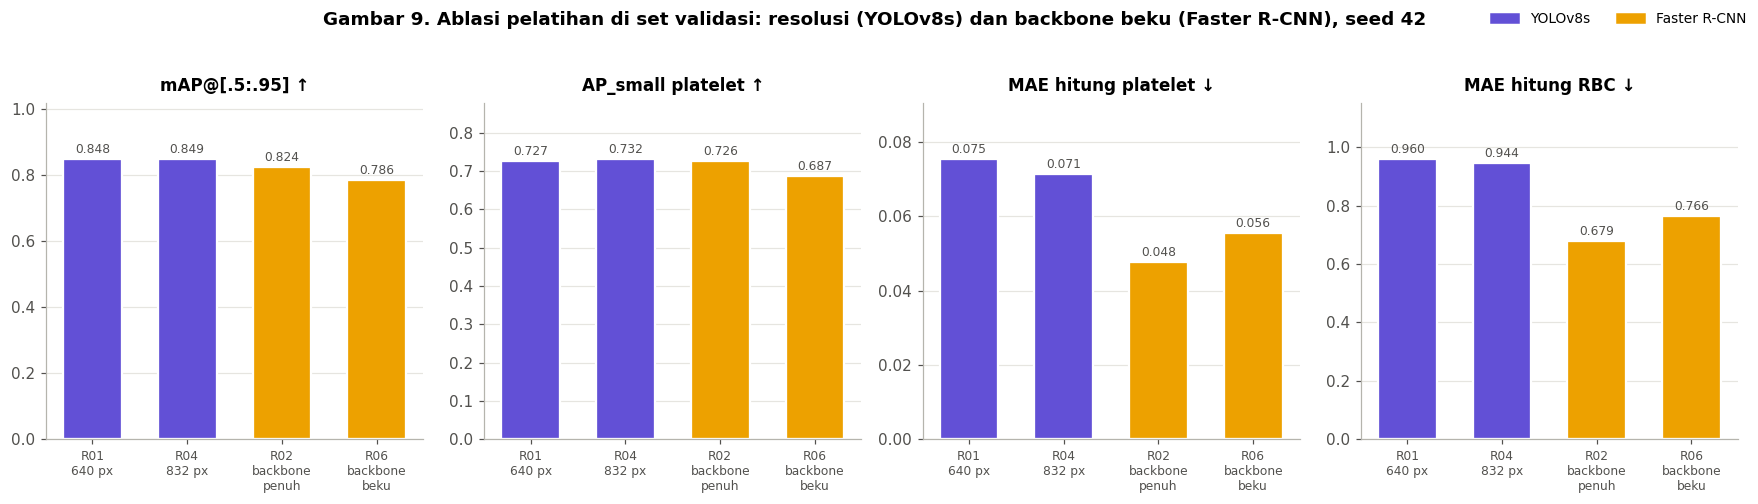

Tersimpan: /content/drive/MyDrive/Colab Notebooks/UAS/outputs/figures/fig9_ablasi_pelatihan.png
Selesai! Arsip M3 diperbarui: /content/drive/MyDrive/Colab Notebooks/UAS/outputs/m3_results_bundle.zip (12.7 MB)


In [6]:
import os, sys, zipfile
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/UAS")
os.chdir(PROJECT_ROOT); sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import style, label_bars, BAR, MODEL_COLORS
style()
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"

# ---- Gambar 9
val = pd.read_csv(PROJECT_ROOT / "outputs" / "eval" / "val_semua_run.csv", index_col=0)
model_of = lambda r: "YOLOv8s" if r.split("-")[0] in ("R01", "R04", "R07", "R08") else "Faster R-CNN"
ABL = [r for r in ["R01", "R04", "R02", "R06"] if r in val.index]
SHORT = {"R01": "640 px", "R04": "832 px", "R02": "backbone\npenuh", "R06": "backbone\nbeku"}
metrics = [("mAP50_95", "mAP@[.5:.95] ↑"), ("AP_small", "AP_small platelet ↑"),
           ("MAE_Platelets", "MAE hitung platelet ↓"), ("MAE_RBC", "MAE hitung RBC ↓")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
colors = [MODEL_COLORS[model_of(r)] for r in ABL]
for ax, (k, t) in zip(axes, metrics):
    v = val.loc[ABL, k].astype(float).values
    bars = ax.bar(range(len(ABL)), v, 0.62, color=colors, **BAR)
    label_bars(ax, bars, "{:.3f}", fontsize=8)
    ax.set_xticks(range(len(ABL)), [f"{r}\n{SHORT[r]}" for r in ABL], fontsize=8)
    ax.set_title(t); ax.set_ylim(0, max(v) * 1.2)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in MODEL_COLORS.values()]
fig.legend(handles, MODEL_COLORS.keys(), loc="upper right", ncol=2)
fig.suptitle("Gambar 9. Ablasi pelatihan di set validasi: resolusi (YOLOv8s) dan backbone beku (Faster R-CNN), seed 42",
             fontweight="semibold", y=1.03)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig9_ablasi_pelatihan.png"); plt.show()
print("Tersimpan:", FIG_DIR / "fig9_ablasi_pelatihan.png")

# ---- Perbarui zip supaya Gambar 9 ikut masuk
bundle = PROJECT_ROOT / "outputs" / "m3_results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["outputs/figures", "outputs/eval", "outputs/eda", "outputs/leakage", "experiments", "configs", "splits"]:
        p = PROJECT_ROOT / folder
        for f in sorted(p.rglob("*")) if p.exists() else []:
            if not f.is_file() or f.suffix.lower() in (".gsheet", ".gdoc", ".gslides", ".gdraw"):
                continue
            try:
                zf.write(f, f.relative_to(PROJECT_ROOT))
            except OSError as e:
                print("dilewati:", f.relative_to(PROJECT_ROOT), f"({e.strerror})")
print(f"Selesai! Arsip M3 diperbarui: {bundle} ({bundle.stat().st_size / 1024**2:.1f} MB)")

=== Ablasi NMS (validasi) ===


,model,iou,mAP50_95,MAE_WBC,MAE_RBC,MAE_Platelets
0,YOLOv8s,0.45,0.8472,0.0079,0.9643,0.0754
1,YOLOv8s,0.60,0.8476,0.0079,0.9643,0.0754
2,YOLOv8s,0.75,0.8482,0.0079,0.9603,0.0754
3,Faster R-CNN,0.45,0.8245,0.0119,0.6786,0.0476
4,Faster R-CNN,0.60,0.8243,0.0119,0.7937,0.0476
5,Faster R-CNN,0.75,0.8245,0.0119,1.0119,0.0476


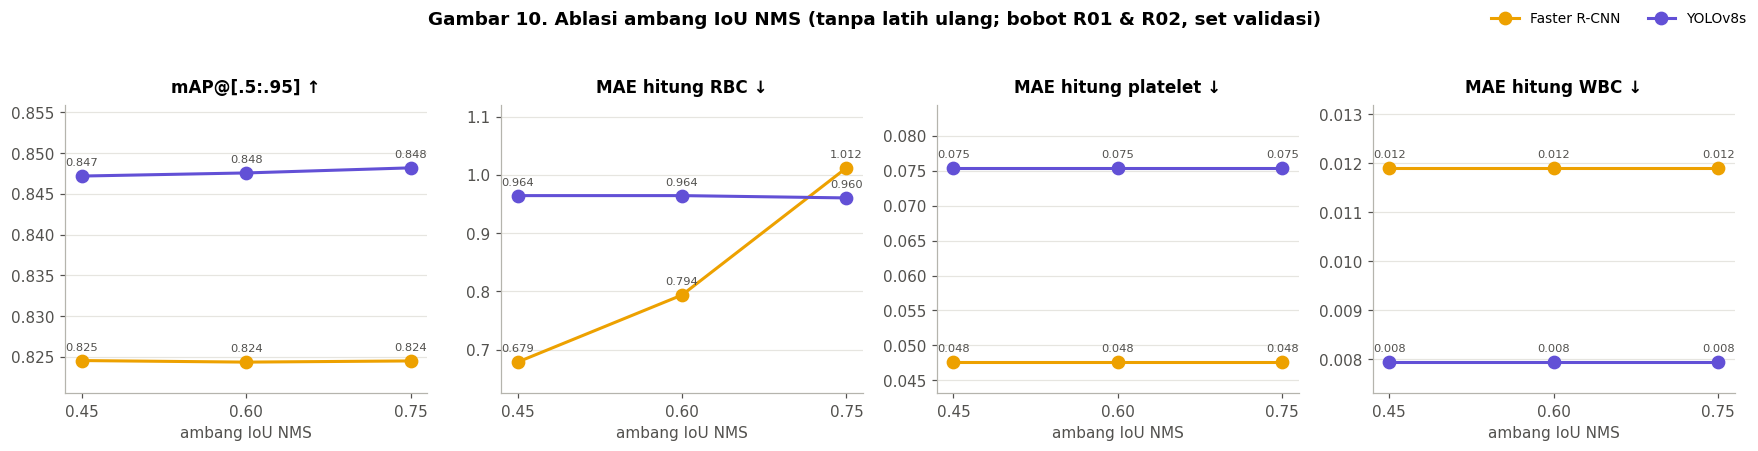

In [9]:
# Gambar 10 · ablasi NMS: mAP dan MAE hitung terhadap ambang IoU NMS (validasi, bobot R01 & R02)
nms_rows = []
for base in ["R01", "R02"]:
    for iou in P.NMS_IOUS:
        vid = P.nms_variant_id(base, iou)
        if vid in val.index:
            nms_rows.append(dict(model=model_of(base), iou=iou, **val.loc[vid, COLS].astype(float).to_dict()))
nms_df = pd.DataFrame(nms_rows)
if len(nms_df):
    nms_df.to_csv(EVAL_DIR / "val_ablasi_nms.csv", index=False)
    print("=== Ablasi NMS (validasi) ===")
    display(nms_df[["model", "iou", "mAP50_95", "MAE_WBC", "MAE_RBC", "MAE_Platelets"]].round(4))
    panels = [("mAP50_95", "mAP@[.5:.95] ↑"), ("MAE_RBC", "MAE hitung RBC ↓"), ("MAE_Platelets", "MAE hitung platelet ↓"), ("MAE_WBC", "MAE hitung WBC ↓")]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
    for ax, (k, t) in zip(axes, panels):
        for g, d in nms_df.groupby("model"):
            ax.plot(d.iou, d[k], marker="o", ms=8, lw=2, color=MODEL_COLORS[g], label=g)
            for x_, y_ in zip(d.iou, d[k]):
                ax.annotate(f"{y_:.3f}", (x_, y_), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7.5, color=INK_2)
        ax.set_xticks(P.NMS_IOUS); ax.set_xlabel("ambang IoU NMS"); ax.set_title(t)
        lo, hi = ax.get_ylim(); ax.set_ylim(lo - (hi - lo) * 0.1, hi + (hi - lo) * 0.25)
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="upper right", ncol=2)
    fig.suptitle("Gambar 10. Ablasi ambang IoU NMS (tanpa latih ulang; bobot R01 & R02, set validasi)", fontweight="semibold", y=1.04)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig10_ablasi_nms.png"); plt.show()
else:
    print("Ablasi NMS belum dijalankan (2.2).")

**Cara menulis di laporan (Bab Hasil → ablasi):** sebutkan pemilik, faktor, nilai yang dibandingkan, dan selisih
metriknya. Contoh: *"Ablasi A1 (Tsabita): menaikkan resolusi 640 → 832 mengubah MAE platelet dari … ke … (…%)."*
Untuk NMS, laporkan rentang MAE RBC antar ambang per model, lalu kaitkan dengan temuan audit (0,29% RBC bertumpuk).

## 3. Perbandingan utama (3 seed), korelasi mAP–MAE & set uji
**Aturan pemilihan (tetap, ditulis sebelum hasil):** konfigurasi dengan **val mAP@[.5:.95] tertinggi** per paradigma
(YOLOv8s: R01 vs R04; Faster R-CNN: R02 vs R06) diulang dengan seed 123 dan 2024. Bersama run seed 42-nya, ini
menjadi perbandingan utama **3 seed** (rerata ± SD). Config R07–R10 ditulis otomatis dan dikunci begitu run dimulai.

### 3.1 YOLOv8s terbaik + seed 123 & 2024 — Tsabita
**Dijalankan:** otomatis setelah R01 dan R04 selesai.

In [10]:
BEST = globals().get("BEST", {})
try:
    BEST["yolo"] = P.choose_best(P.YOLO_CANDIDATES)
    print(f"YOLOv8s terbaik di validasi: {BEST['yolo']} · {label(BEST['yolo'])}")
    P.prepare_seed_configs("yolo", BEST["yolo"])
    for i, r in enumerate(["R07", "R08"], 1):
        jalankan(r, i, 2)
except RuntimeError as e:
    print(e)

YOLOv8s terbaik di validasi: R04 · YOLOv8s · 832 · NMS 0,70
R07: mewarisi R04, seed 123
R08: mewarisi R04, seed 2024
[1/2] MULAI R07 · Faster R-CNN · R04 seed 123 · VRAM terpakai sebelum: 0.10 GB
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_txl.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.0, hsv_v=0.0, imgsz=832, iou=None, kobj=1.0, line_width=None, lr0=0.01, 

### 3.2 Faster R-CNN terbaik + seed 123 & 2024 — Putri
**Dijalankan:** otomatis setelah R02 dan R06 selesai.

In [11]:
try:
    BEST["frcnn"] = P.choose_best(P.FRCNN_CANDIDATES)
    print(f"Faster R-CNN terbaik di validasi: {BEST['frcnn']} · {label(BEST['frcnn'])}")
    P.prepare_seed_configs("frcnn", BEST["frcnn"])
    for i, r in enumerate(["R09", "R10"], 1):
        jalankan(r, i, 2)
except RuntimeError as e:
    print(e)

GROUPS = {}
if "yolo" in BEST:
    GROUPS["YOLOv8s"] = [BEST["yolo"], "R07", "R08"]
if "frcnn" in BEST:
    GROUPS["Faster R-CNN"] = [BEST["frcnn"], "R09", "R10"]
GROUPS = {g: rs for g, rs in GROUPS.items() if all(r in val.index or (PRED_DIR / f"{r}_val.json").exists() for r in rs)}

Faster R-CNN terbaik di validasi: R02 · Faster R-CNN · penuh · NMS 0,50
R09: mewarisi R02, seed 123
R10: mewarisi R02, seed 2024
[1/2] MULAI R09 · Faster R-CNN · R02 seed 123 · VRAM terpakai sebelum: 0.10 GB
  epoch 1 iter 50/220 loss 1.2340 lr 0.00164
  epoch 1 iter 100/220 loss 0.8670 lr 0.00331
  epoch 1 iter 150/220 loss 0.7106 lr 0.00497
  epoch 1 iter 200/220 loss 0.6269 lr 0.00664
epoch 1/12  loss 0.6045  val mAP50 nan  mAP50-95 nan  GPU puncak 5.5 GB  (1.8 mnt)
  epoch 2 iter 50/220 loss 0.3812 lr 0.00897
  epoch 2 iter 100/220 loss 0.3594 lr 0.01000
  epoch 2 iter 150/220 loss 0.3496 lr 0.01000
  epoch 2 iter 200/220 loss 0.3421 lr 0.01000
epoch 2/12  loss 0.3390  val mAP50 nan  mAP50-95 nan  GPU puncak 5.6 GB  (1.8 mnt)
  epoch 3 iter 50/220 loss 0.3043 lr 0.01000
  epoch 3 iter 100/220 loss 0.2935 lr 0.01000
  epoch 3 iter 150/220 loss 0.2896 lr 0.01000
  epoch 3 iter 200/220 loss 0.2802 lr 0.01000
epoch 3/12  loss 0.2787  val mAP50 nan  mAP50-95 nan  GPU puncak 5.6 GB  (1.8

### 3.3 Korelasi Pearson/Spearman mAP vs MAE antar run (validasi) — Tsabita
**Metrik fokus T1-A.** Setiap run dan varian NMS menjadi satu titik (mAP@[.5:.95], MAE hitung per kelas). Korelasi dihitung
untuk gabungan run dan per paradigma. **Cara membaca:** ρ mendekati −1 berarti mAP naik → galat hitung turun (mAP
cukup mewakili hitungan); |ρ| kecil berarti mAP **tidak** menjamin hitungan akurat (H1). n kecil → p-value indikatif.

=== Perbandingan utama di VALIDASI · rerata ± SD (3 seed) ===


,YOLOv8s,Faster R-CNN
mAP50,0.9747 ± 0.0040,0.9819 ± 0.0011
mAP50_95,0.8496 ± 0.0018,0.8277 ± 0.0048
AP_small,0.7391 ± 0.0142,0.7259 ± 0.0003
AP_medium,0.8617 ± 0.0026,0.8336 ± 0.0081
AP_large,0.8879 ± 0.0015,0.8588 ± 0.0036
AP50_95_WBC,0.8918 ± 0.0007,0.8565 ± 0.0063
AP50_95_RBC,0.8898 ± 0.0025,0.8710 ± 0.0005
AP50_95_Platelets,0.7671 ± 0.0051,0.7556 ± 0.0088
MAE_WBC,0.0093 ± 0.0023,0.0119 ± 0.0000
MAE_RBC,0.9590 ± 0.0139,0.7143 ± 0.0458


=== Korelasi antar run di validasi (n = 14; p-value indikatif) ===


,kelompok,kelas,x,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,semua run,WBC,mAP50_95,14,-0.934,0.000,-0.767,0.001
1,semua run,WBC,AP50_95_WBC,14,-0.885,0.000,-0.745,0.002
2,semua run,RBC,mAP50_95,14,0.634,0.015,0.516,0.059
3,semua run,RBC,AP50_95_RBC,14,0.596,0.025,0.554,0.040
4,semua run,Platelets,mAP50_95,14,0.703,0.005,0.688,0.006
5,semua run,Platelets,AP50_95_Platelets,14,0.621,0.018,0.700,0.005
6,Faster R-CNN,WBC,mAP50_95,7,-0.979,0.000,-0.612,0.144
7,Faster R-CNN,WBC,AP50_95_WBC,7,-0.974,0.000,-0.676,0.096
8,Faster R-CNN,RBC,mAP50_95,7,0.006,0.990,-0.055,0.908
9,Faster R-CNN,RBC,AP50_95_RBC,7,0.021,0.964,0.036,0.938


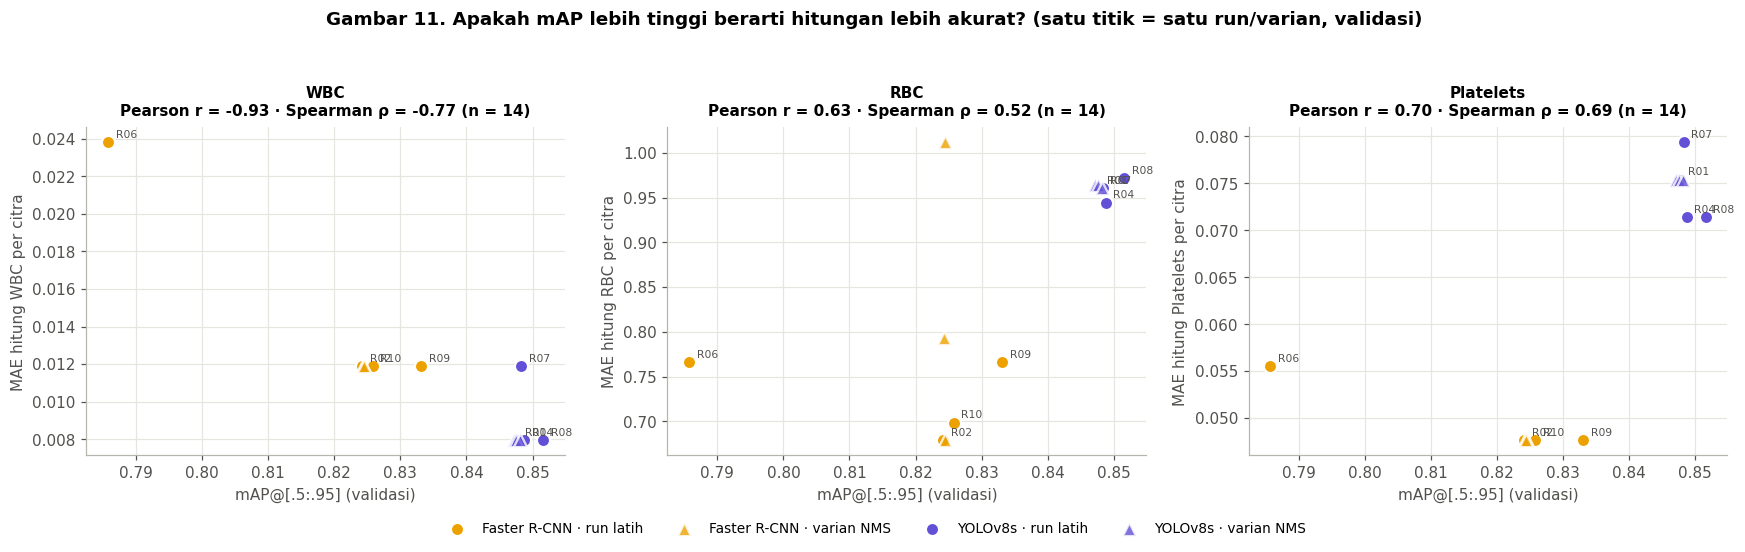

In [12]:
# tambahkan run yang baru selesai di sesi ini (3.1/3.2) ke tabel validasi
baru = [r for r in runs_done() if r not in val.index and (PRED_DIR / f"{r}_val.json").exists()]
if baru:
    val = pd.concat([val.drop(columns="model"), eval_runs(baru, "val")])
    val["model"] = [model_of(r) for r in val.index]
if GROUPS:
    num_val, txt_val = mean_sd(val, GROUPS, COLS)
    num_val.to_csv(EVAL_DIR / "val_utama_mean_sd.csv")
    print("=== Perbandingan utama di VALIDASI · rerata ± SD (3 seed) ===")
    display(txt_val.T)
if len(val) >= 3:
    corr_val = correlation_table(val)
    corr_val.to_csv(EVAL_DIR / "val_korelasi_map_mae.csv", index=False)
    print(f"=== Korelasi antar run di validasi (n = {len(val)}; p-value indikatif) ===")
    display(corr_val.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    for ax, c in zip(axes, CLASSES):
        for g, d in val.groupby("model"):
            is_nms = d.index.str.contains("-nms")
            ax.scatter(d[~is_nms].mAP50_95.astype(float), d[~is_nms][f"MAE_{c}"].astype(float), s=75, marker="o",
                       color=MODEL_COLORS[g], edgecolor="white", linewidth=1.5, label=f"{g} · run latih", zorder=3)
            ax.scatter(d[is_nms].mAP50_95.astype(float), d[is_nms][f"MAE_{c}"].astype(float), s=75, marker="^",
                       color=MODEL_COLORS[g], edgecolor="white", linewidth=1.5, alpha=0.8, label=f"{g} · varian NMS", zorder=3)
            for r_, row in d[~is_nms].iterrows():
                ax.annotate(r_, (float(row.mAP50_95), float(row[f"MAE_{c}"])), xytext=(5, 3), textcoords="offset points",
                            fontsize=7, color=INK_2)
        rr = corr_val[(corr_val.kelompok == "semua run") & (corr_val.kelas == c) & (corr_val.x == "mAP50_95")]
        sub = f"\nPearson r = {rr.pearson_r.iloc[0]:.2f} · Spearman ρ = {rr.spearman_rho.iloc[0]:.2f} (n = {len(val)})" if len(rr) else ""
        ax.set_title(f"{c}{sub}", fontsize=10)
        ax.set_xlabel("mAP@[.5:.95] (validasi)"); ax.set_ylabel(f"MAE hitung {c} per citra"); ax.grid(axis="x")
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("Gambar 11. Apakah mAP lebih tinggi berarti hitungan lebih akurat? (satu titik = satu run/varian, validasi)",
                 fontweight="semibold", y=1.05)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig11_korelasi_map_mae.png"); plt.show()
else:
    corr_val = pd.DataFrame()
    print("Korelasi butuh minimal 3 run selesai.")

### 3.4 Set uji (dibuka satu kali) — Putri
Hanya **6 run final** (3 seed × 2 model) yang diprediksi pada set uji. τ setiap run berasal dari validasi; tidak ada
penyesuaian apa pun di set uji. Waktu pembukaan dicatat di `outputs/eval/SET_UJI_DIBUKA.txt`; bila berkas itu sudah
ada, prediksi uji **tidak** dibuat ulang.

**Dijalankan:** otomatis **satu kali** begitu keenam run final selesai (pemilik: Putri).
**Keluaran:** tabel utama rerata ± SD, uji statistik berpasangan, hasil per ukuran objek (K5), galat per kepadatan & sumber.

In [13]:
FINAL = [r for rs in GROUPS.values() for r in rs] if len(GROUPS) == 2 else []
if FINAL and not TEST_MARKER.exists() and boleh("UJI"):
    import datetime as dt
    TEST_MARKER.write_text(f"Set uji dibuka {dt.datetime.now():%Y-%m-%d %H:%M} untuk {FINAL}\n")
    for r in FINAL:
        if not (PRED_DIR / f"{r}_test.json").exists():
            P.run_isolated(f"test:{r}", DATA_ROOT)        # proses terpisah agar VRAM tidak menumpuk
        print(f"{r}: prediksi uji disimpan")
elif TEST_MARKER.exists():
    for r in [r for r in FINAL if not (PRED_DIR / f"{r}_test.json").exists()]:
        if boleh("UJI"):                                   # melengkapi bila sesi putus saat prediksi uji
            P.run_isolated(f"test:{r}", DATA_ROOT); print(f"{r}: prediksi uji dilengkapi")
    print(TEST_MARKER.read_text().strip(), "· memakai prediksi yang sudah ada (tidak diprediksi ulang)")
elif FINAL:
    print(f"TUNDA: membuka set uji · {'GPU tidak aktif' if not GPU_OK else 'milik Putri'}")
else:
    print("Set uji masih DIKUNCI: menunggu keenam run final (R07–R10) selesai.")
TEST_OK = bool(TEST_MARKER.exists() and FINAL and all((PRED_DIR / f"{r}_test.json").exists() for r in FINAL))

if TEST_OK:
    test = eval_runs(FINAL, "test")
    test["model"] = [model_of(r) for r in test.index]
    test.to_csv(EVAL_DIR / "test_final_per_run.csv")
    num_test, txt_test = mean_sd(test, GROUPS, COLS)
    num_test.to_csv(EVAL_DIR / "test_utama_mean_sd.csv")
    print("=== TABEL UTAMA · set uji · rerata ± SD (3 seed) ===")
    display(txt_test.T)

R04: prediksi uji disimpan
R07: prediksi uji disimpan
R08: prediksi uji disimpan
R02: prediksi uji disimpan
R09: prediksi uji disimpan
R10: prediksi uji disimpan
=== TABEL UTAMA · set uji · rerata ± SD (3 seed) ===


,YOLOv8s,Faster R-CNN
mAP50,0.9834 ± 0.0029,0.9922 ± 0.0008
mAP50_95,0.8629 ± 0.0053,0.8481 ± 0.0019
AP_small,0.7841 ± 0.0150,0.8021 ± 0.0093
AP_medium,0.8739 ± 0.0014,0.8592 ± 0.0061
AP_large,0.6630 ± 0.1171,0.7882 ± 0.0387
AP50_95_WBC,0.8863 ± 0.0078,0.8473 ± 0.0071
AP50_95_RBC,0.8922 ± 0.0024,0.8754 ± 0.0012
AP50_95_Platelets,0.8103 ± 0.0099,0.8215 ± 0.0046
MAE_WBC,0.0132 ± 0.0046,0.0079 ± 0.0079
MAE_RBC,0.9048 ± 0.0346,0.7857 ± 0.0346


In [14]:
# Uji statistik berpasangan YOLOv8s vs Faster R-CNN (pasangan = seed yang sama), seperti di referensi
if TEST_OK:
    from scipy.stats import ttest_rel, wilcoxon
    seed_of = read_log().set_index("run_id").seed.astype(int)
    ya = sorted(GROUPS["YOLOv8s"], key=lambda r: seed_of[r])
    fa = sorted(GROUPS["Faster R-CNN"], key=lambda r: seed_of[r])
    rows = []
    for k in ["mAP50", "mAP50_95", "AP_small"] + [f"AP50_95_{c}" for c in CLASSES] + [f"MAE_{c}" for c in CLASSES]:
        a, b = test.loc[ya, k].astype(float).values, test.loc[fa, k].astype(float).values
        t, p = ttest_rel(b, a)
        try:
            pw = wilcoxon(b, a).pvalue
        except ValueError:
            pw = np.nan
        sp = np.sqrt((a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2) / 2)
        rows.append(dict(metrik=k, YOLOv8s=f"{a.mean():.4f} ± {a.std(ddof=1):.4f}", Faster_RCNN=f"{b.mean():.4f} ± {b.std(ddof=1):.4f}",
                         selisih_FRCNN_minus_YOLO=b.mean() - a.mean(), t_stat=t, p_ttest_paired=p, p_wilcoxon=pw,
                         bermakna_2xSD=abs(b.mean() - a.mean()) > 2 * sp))
    stat_tab = pd.DataFrame(rows)
    stat_tab.to_csv(EVAL_DIR / "test_uji_statistik.csv", index=False)
    print(f"=== UJI STATISTIK BERPASANGAN (pasangan seed: {list(zip(ya, fa))}) ===")
    print("Catatan: n = 3 pasangan → Wilcoxon tidak bisa < 0,25; keputusan utama memakai aturan 2 × SD dari proposal.")
    display(stat_tab.round(4))

    print("\n=== HASIL PER UKURAN OBJEK (K5) · AP COCO small / medium / large, set uji ===")
    display(txt_test.T.loc[["AP_small", "AP_medium", "AP_large"]])

    corr_test = correlation_table(test)
    corr_test.to_csv(EVAL_DIR / "test_korelasi_map_mae.csv", index=False)
    print(f"\n=== Korelasi mAP vs MAE antar 6 run final di set uji (n = {len(test)}, indikatif) ===")
    display(corr_test[corr_test.kelompok == "semua run"].round(3))

=== UJI STATISTIK BERPASANGAN (pasangan seed: [('R04', 'R02'), ('R07', 'R09'), ('R08', 'R10')]) ===
Catatan: n = 3 pasangan → Wilcoxon tidak bisa < 0,25; keputusan utama memakai aturan 2 × SD dari proposal.


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:423: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return hypotest_fun_in(*args, **kwds)


,metrik,YOLOv8s,Faster_RCNN,selisih_FRCNN_minus_YOLO,t_stat,p_ttest_paired,p_wilcoxon,bermakna_2xSD
0,mAP50,0.9834 ± 0.0029,0.9922 ± 0.0008,0.0088,4.735100e+00,0.0418,0.25,True
1,mAP50_95,0.8629 ± 0.0053,0.8481 ± 0.0019,-0.0148,-4.307100e+00,0.0499,0.25,True
2,AP_small,0.7841 ± 0.0150,0.8021 ± 0.0093,0.0179,2.817600e+00,0.1063,0.25,False
3,AP50_95_WBC,0.8863 ± 0.0078,0.8473 ± 0.0071,-0.0390,-4.950800e+00,0.0385,0.25,True
4,AP50_95_RBC,0.8922 ± 0.0024,0.8754 ± 0.0012,-0.0167,-9.592100e+00,0.0107,0.25,True
5,AP50_95_Platelets,0.8103 ± 0.0099,0.8215 ± 0.0046,0.0113,2.228000e+00,0.1557,0.25,False
6,MAE_WBC,0.0132 ± 0.0046,0.0079 ± 0.0079,-0.0053,-1.000000e+00,0.4226,1.00,False
7,MAE_RBC,0.9048 ± 0.0346,0.7857 ± 0.0346,-0.1190,-3.204364e+15,0.0000,0.25,True
8,MAE_Platelets,0.0476 ± 0.0238,0.0317 ± 0.0079,-0.0159,-8.660000e-01,0.4778,0.75,False



=== HASIL PER UKURAN OBJEK (K5) · AP COCO small / medium / large, set uji ===


,YOLOv8s,Faster R-CNN
AP_small,0.7841 ± 0.0150,0.8021 ± 0.0093
AP_medium,0.8739 ± 0.0014,0.8592 ± 0.0061
AP_large,0.6630 ± 0.1171,0.7882 ± 0.0387



=== Korelasi mAP vs MAE antar 6 run final di set uji (n = 6, indikatif) ===


,kelompok,kelas,x,n,pearson_r,p_pearson,spearman_rho,p_spearman
0,semua run,WBC,mAP50_95,6,0.401,0.430,0.463,0.355
1,semua run,WBC,AP50_95_WBC,6,0.514,0.297,0.463,0.355
2,semua run,RBC,mAP50_95,6,0.755,0.083,0.714,0.111
3,semua run,RBC,AP50_95_RBC,6,0.838,0.037,0.714,0.111
4,semua run,Platelets,mAP50_95,6,0.748,0.087,0.696,0.125
5,semua run,Platelets,AP50_95_Platelets,6,0.195,0.712,-0.029,0.957


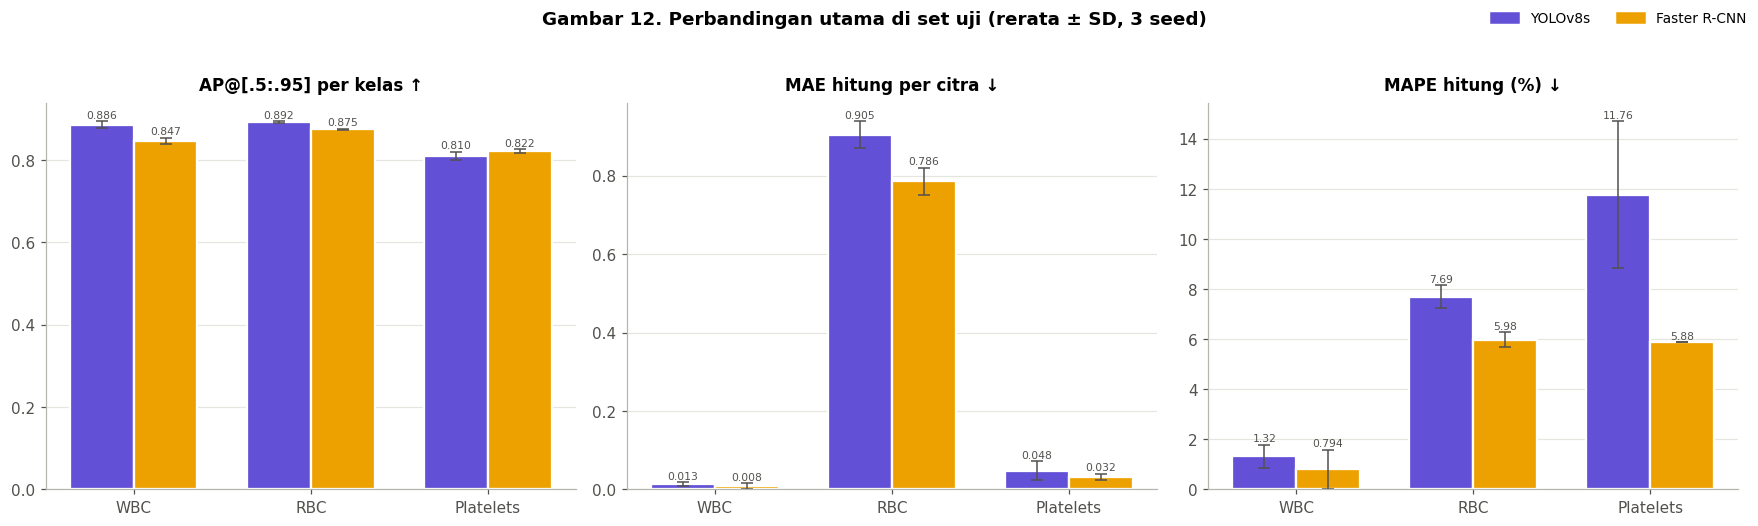

In [15]:
# Gambar 12 · perbandingan utama di set uji (rerata ± SD 3 seed)
if TEST_OK:
    panels = [("AP50_95_{}", "AP@[.5:.95] per kelas ↑"), ("MAE_{}", "MAE hitung per citra ↓"), ("MAPE_{}", "MAPE hitung (%) ↓")]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    w = 0.36
    for ax, (k, t) in zip(axes, panels):
        for i, g in enumerate(GROUPS):
            m = [num_test.loc[(g, "mean"), k.format(c)] for c in CLASSES]
            s = [num_test.loc[(g, "sd"), k.format(c)] for c in CLASSES]
            bars = ax.bar(np.arange(3) + (i - 0.5) * w, m, w, yerr=s, capsize=4, color=MODEL_COLORS[g], label=g,
                          error_kw=dict(ecolor=INK_2, lw=1), **BAR)
            for b_, mm, ss in zip(bars, m, s):
                ax.annotate(f"{mm:.2f}" if mm >= 1 else f"{mm:.3f}", (b_.get_x() + b_.get_width() / 2, mm + ss),
                            xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7, color=INK_2)
        ax.set_xticks(range(3), CLASSES); ax.set_title(t)
    handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[g]) for g in GROUPS]
    fig.legend(handles, list(GROUPS), loc="upper right", ncol=2)
    fig.suptitle("Gambar 12. Perbandingan utama di set uji (rerata ± SD, 3 seed)", fontweight="semibold", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig12_utama_set_uji.png"); plt.show()

=== MAE dan bias hitung RBC per kepadatan (rerata ± SD antar seed; bias < 0 = kurang hitung) ===


MAE          bias       
                      mean    std   mean    std
model        padat                             
Faster R-CNN RBC>15  1.412  0.147  0.549  0.177
             RBC≤15  0.554  0.033  0.322  0.051
YOLOv8s      RBC>15  1.039  0.034  0.235  0.156
             RBC≤15  0.855  0.056  0.572  0.023

=== MAE hitung per sumber (rerata 3 seed) ===


kelas                      WBC    RBC  Platelets
model        source                             
Faster R-CNN BCCD        0.000  1.556      0.000
             BCDD        0.000  0.524      0.000
             PBC         0.007  0.700      0.020
             Raabin-WBC  0.015  0.652      0.068
YOLOv8s      BCCD        0.000  1.037      0.074
             BCDD        0.095  1.238      0.000
             PBC         0.007  0.760      0.047
             Raabin-WBC  0.000  0.909      0.053

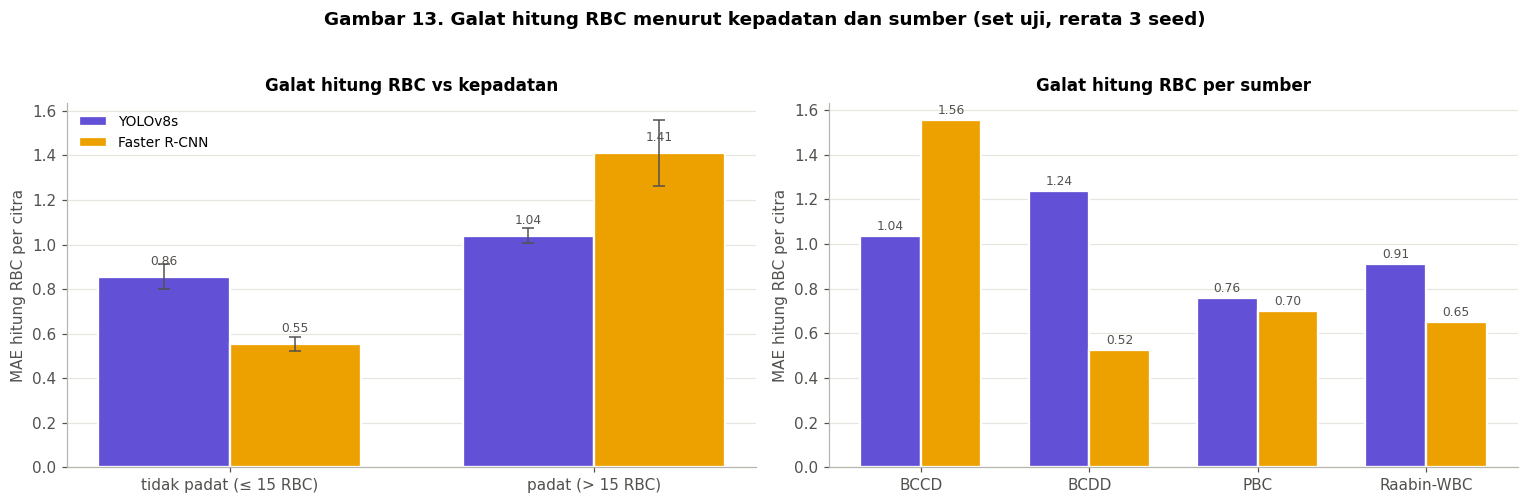

In [16]:
# Gambar 13 · galat hitung RBC per kepadatan dan per sumber (set uji, rerata 3 seed)
if TEST_OK:
    pe = per_image_errors(FINAL, "test", DATA_ROOT)
    pe["model"] = pe.run.map({r: g for g, rs in GROUPS.items() for r in rs})
    pe.to_csv(EVAL_DIR / "test_galat_per_citra.csv", index=False)
    h2 = pe[pe.kelas == "RBC"].groupby(["model", "padat", "run"]).agg(MAE=("abs_err", "mean"), bias=("err", "mean")).groupby(level=[0, 1]).agg(["mean", "std"])
    print("=== MAE dan bias hitung RBC per kepadatan (rerata ± SD antar seed; bias < 0 = kurang hitung) ===")
    display(h2.round(3))
    src_tab = pe.groupby(["model", "source", "kelas", "run"]).abs_err.mean().groupby(level=[0, 1, 2]).mean().unstack("kelas")[CLASSES]
    print("=== MAE hitung per sumber (rerata 3 seed) ===")
    display(src_tab.round(3))
    src_tab.to_csv(EVAL_DIR / "test_mae_per_sumber.csv")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
    w = 0.36
    ax = axes[0]
    for i, g in enumerate(GROUPS):
        m = [h2.loc[(g, p), ("MAE", "mean")] for p in ["RBC≤15", "RBC>15"]]
        s = [h2.loc[(g, p), ("MAE", "std")] for p in ["RBC≤15", "RBC>15"]]
        bars = ax.bar(np.arange(2) + (i - 0.5) * w, m, w, yerr=s, capsize=4, color=MODEL_COLORS[g], label=g,
                      error_kw=dict(ecolor=INK_2, lw=1), **BAR)
        label_bars(ax, bars, "{:.2f}", fontsize=8, pad=6)
    ax.set_xticks(range(2), ["tidak padat (≤ 15 RBC)", "padat (> 15 RBC)"]); ax.set_ylabel("MAE hitung RBC per citra")
    ax.set_title("Galat hitung RBC vs kepadatan"); ax.legend()
    ax = axes[1]
    srcs = sorted(pe.source.unique())
    for i, g in enumerate(GROUPS):
        bars = ax.bar(np.arange(len(srcs)) + (i - 0.5) * w, [src_tab.loc[(g, s_), "RBC"] for s_ in srcs], w,
                      color=MODEL_COLORS[g], label=g, **BAR)
        label_bars(ax, bars, "{:.2f}", fontsize=8)
    ax.set_xticks(range(len(srcs)), srcs); ax.set_ylabel("MAE hitung RBC per citra"); ax.set_title("Galat hitung RBC per sumber")
    fig.suptitle("Gambar 13. Galat hitung RBC menurut kepadatan dan sumber (set uji, rerata 3 seed)", fontweight="semibold", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig13_kepadatan_sumber.png"); plt.show()

**Cara menulis di laporan (Bab Hasil → tabel utama):** tabel utama memakai angka **set uji** rerata ± SD 3 seed.
Sebut perbedaan bermakna hanya bila kolom `bermakna_2xSD` = True. Jawaban RQ diambil dari Gambar 11 (korelasi di
validasi, n besar) dan didukung korelasi 6 run di set uji.

## 4. Efisiensi & kelayakan penerapan (K7) — Tsabita
| | |
|---|---|
| **Diukur** | jumlah parameter (juta) dan latensi ujung ke ujung per citra (pra-proses → model → NMS) |
| **Protokol** | batch 1, warm-up 10 citra, rerata 50 citra validasi, GPU T4 Colab, konfigurasi final seed 42 |
| **Dijalankan** | otomatis setelah konfigurasi final ditetapkan; hasil disimpan ke Drive dan dipakai ulang (pemilik: Tsabita) |
| **Keluaran** | `outputs/eval/efisiensi.csv`, Gambar 14 (trade-off akurasi–kecepatan) |

In [17]:
from src.efficiency import yolo_efficiency, frcnn_efficiency
val_imgs = [DATA_ROOT / "images" / "val" / n for n in (SPLIT_DIR / "val.txt").read_text().split()[:60]]   # 10 warm-up + 50 diukur
for kind in [k for k in ["yolo", "frcnn"] if k in BEST and not (EVAL_DIR / f"efisiensi_{k}.json").exists()]:
    if not boleh("EFISIENSI"):
        print(f"TUNDA: efisiensi {kind} · {'GPU tidak aktif' if not GPU_OK else 'milik Tsabita'}")
        continue
    r = BEST[kind]
    cfg = load_config(r)
    if kind == "yolo":
        eff = yolo_efficiency(RUNS_DIR / r / "weights" / "best.pt", val_imgs, cfg)
    else:
        from src import frcnn
        model = frcnn.load_best(cfg, RUNS_DIR / r, device="cuda")
        eff = frcnn_efficiency(model, val_imgs)
        del model
    eff.update(run=r, model="YOLOv8s" if kind == "yolo" else "Faster R-CNN", gpu=torch.cuda.get_device_name(0))
    (EVAL_DIR / f"efisiensi_{kind}.json").write_text(json.dumps(eff, indent=1))
    print(kind, eff)
    P.free_gpu()

effs = [json.loads((EVAL_DIR / f"efisiensi_{k}.json").read_text()) for k in ["yolo", "frcnn"] if (EVAL_DIR / f"efisiensi_{k}.json").exists()]
if effs:
    eff_tab = pd.DataFrame(effs).set_index("model")[["run", "parameter_juta", "latensi_ms_mean", "latensi_ms_std", "latensi_ms_median", "n_citra", "warmup", "gpu"]]
    eff_tab["citra_per_detik"] = 1000 / eff_tab.latensi_ms_mean
    eff_tab.to_csv(EVAL_DIR / "efisiensi.csv")
    print("=== TABEL EFISIENSI MODEL (K7: BATCH 1 SETELAH 10 WARM-UP, 50 CITRA) ===")
    display(eff_tab.round(2))
else:
    print("Efisiensi belum diukur.")

yolo {'latensi_ms_mean': 20.058300559903728, 'latensi_ms_std': 1.1322080542911832, 'latensi_ms_median': 19.93574849984725, 'n_citra': 50, 'warmup': 10, 'parameter_juta': 11.136761, 'run': 'R04', 'model': 'YOLOv8s', 'gpu': 'Tesla T4'}
VRAM terpakai sekarang: 0.00 GB
frcnn {'latensi_ms_mean': 66.29101609993086, 'latensi_ms_std': 6.0574836674555215, 'latensi_ms_median': 64.45520400029636, 'n_citra': 50, 'warmup': 10, 'parameter_juta': 41.309411, 'run': 'R02', 'model': 'Faster R-CNN', 'gpu': 'Tesla T4'}
VRAM terpakai sekarang: 0.06 GB
=== TABEL EFISIENSI MODEL (K7: BATCH 1 SETELAH 10 WARM-UP, 50 CITRA) ===


,run,parameter_juta,latensi_ms_mean,latensi_ms_std,latensi_ms_median,n_citra,warmup,gpu,citra_per_detik
model,,,,,,,,,
YOLOv8s,R04,11.14,20.06,1.13,19.94,50,10,Tesla T4,49.85
Faster R-CNN,R02,41.31,66.29,6.06,64.46,50,10,Tesla T4,15.09


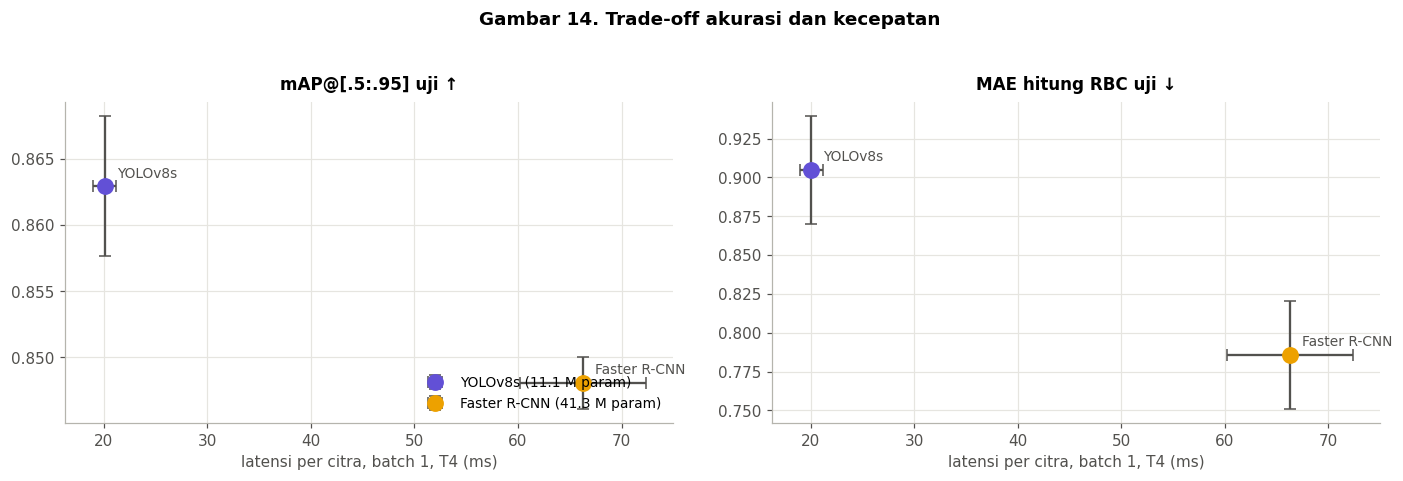

In [18]:
# Gambar 14 · trade-off akurasi–kecepatan (set uji, rerata 3 seed)
if effs and TEST_OK and len(effs) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (k, t) in zip(axes, [("mAP50_95", "mAP@[.5:.95] uji ↑"), ("MAE_RBC", "MAE hitung RBC uji ↓")]):
        for e in effs:
            g = e["model"]
            y, s = num_test.loc[(g, "mean"), k], num_test.loc[(g, "sd"), k]
            ax.errorbar(e["latensi_ms_mean"], y, yerr=s, xerr=e["latensi_ms_std"], fmt="o", ms=10, color=MODEL_COLORS[g],
                        ecolor=INK_2, capsize=4, label=f"{g} ({e['parameter_juta']:.1f} M param)")
            ax.annotate(g, (e["latensi_ms_mean"], y), xytext=(8, 6), textcoords="offset points", fontsize=9, color=INK_2)
        ax.set_xlabel("latensi per citra, batch 1, T4 (ms)"); ax.set_title(t); ax.grid(axis="x")
    axes[0].legend(loc="lower right")
    fig.suptitle("Gambar 14. Trade-off akurasi dan kecepatan", fontweight="semibold", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig14_tradeoff_efisiensi.png"); plt.show()

**Cara menulis di laporan (Diskusi → kelayakan):** kaitkan latensi dengan konteks laboratorium, misalnya berapa
lapang pandang per detik yang bisa diproses, dan apakah selisih galat hitung sepadan dengan selisih kecepatan.

## 5. Analisis kesalahan & interpretabilitas (K6)
### 5.1 Analisis kesalahan berkategori + galeri — Putri
Deteksi dengan skor ≥ τ (dari validasi) dicocokkan dengan ground truth (IoU ≥ 0,5, sekelas). Setiap FN/FP diberi
kategori otomatis (aturan di `src/errors.py`): **FN** = salah kelas, objek kecil, terpotong tepi, bertumpuk, terlewat
lain; **FP** = salah kelas, deteksi ganda, lokalisasi buruk, partikel kecil, latar/artefak. Dianalisis pada konfigurasi
final seed 42 di set uji (atau validasi bila set uji belum dibuka). **Keluaran:** tabel frekuensi, Gambar 15–16.

In [19]:
from src.errors import match, category_table, prf, FN_CATS, FP_CATS
from src.summary import tau_from_val
SPLIT_AN = "test" if TEST_OK else "val"
AN_RUNS = {("YOLOv8s" if k == "yolo" else "Faster R-CNN"): r for k, r in BEST.items() if (PRED_DIR / f"{r}_{SPLIT_AN}.json").exists()}
gt_an = load_json(COCO_DIR / f"{SPLIT_AN}.json")
imgs_an = {im["id"]: im for im in gt_an["images"]}
MATCH = {}
for g, r in AN_RUNS.items():
    MATCH[g] = match(gt_an, load_json(PRED_DIR / f"{r}_{SPLIT_AN}.json"), tau_from_val(r))
    print(f"=== {g} ({r}) · set {SPLIT_AN} · presisi/recall/F1 pada τ ===")
    display(prf(MATCH[g]).round(3))
    print(f"=== {g} · FREKUENSI KATEGORI KESALAHAN ===")
    ct = category_table(MATCH[g])
    display(ct)
    ct.to_csv(EVAL_DIR / f"kategori_kesalahan_{r}_{SPLIT_AN}.csv")

=== YOLOv8s (R04) · set test · presisi/recall/F1 pada τ ===


,TP,FP,FN,presisi,recall,F1
kelas,,,,,,
WBC,130,0,1,1.000,0.992,0.996
RBC,1634,111,54,0.936,0.968,0.952
Platelets,45,2,4,0.957,0.918,0.938


=== YOLOv8s · FREKUENSI KATEGORI KESALAHAN ===


kelas                   WBC  RBC  Platelets  total  % dalam jenis
jenis kategori                                                   
FN    bertumpuk           0    4          0      4            6.8
      objek kecil         0    0          1      1            1.7
      terlewat lain       1   21          3     25           42.4
      terpotong tepi      0   29          0     29           49.2
FP    deteksi ganda       0    4          0      4            3.5
      latar/artefak       0   73          1     74           65.5
      lokalisasi buruk    0   34          0     34           30.1
      partikel kecil      0    0          1      1            0.9

=== Faster R-CNN (R02) · set test · presisi/recall/F1 pada τ ===


,TP,FP,FN,presisi,recall,F1
kelas,,,,,,
WBC,131,1,0,0.992,1.000,0.996
RBC,1644,92,44,0.947,0.974,0.960
Platelets,47,2,2,0.959,0.959,0.959


=== Faster R-CNN · FREKUENSI KATEGORI KESALAHAN ===


kelas                   WBC  RBC  Platelets  total  % dalam jenis
jenis kategori                                                   
FN    bertumpuk           0    3          0      3            6.5
      salah kelas         0    0          1      1            2.2
      terlewat lain       0    9          1     10           21.7
      terpotong tepi      0   32          0     32           69.6
FP    deteksi ganda       0    8          0      8            8.4
      latar/artefak       0   36          1     37           38.9
      lokalisasi buruk    0   47          0     47           49.5
      partikel kecil      0    0          1      1            1.1
      salah kelas         1    1          0      2            2.1

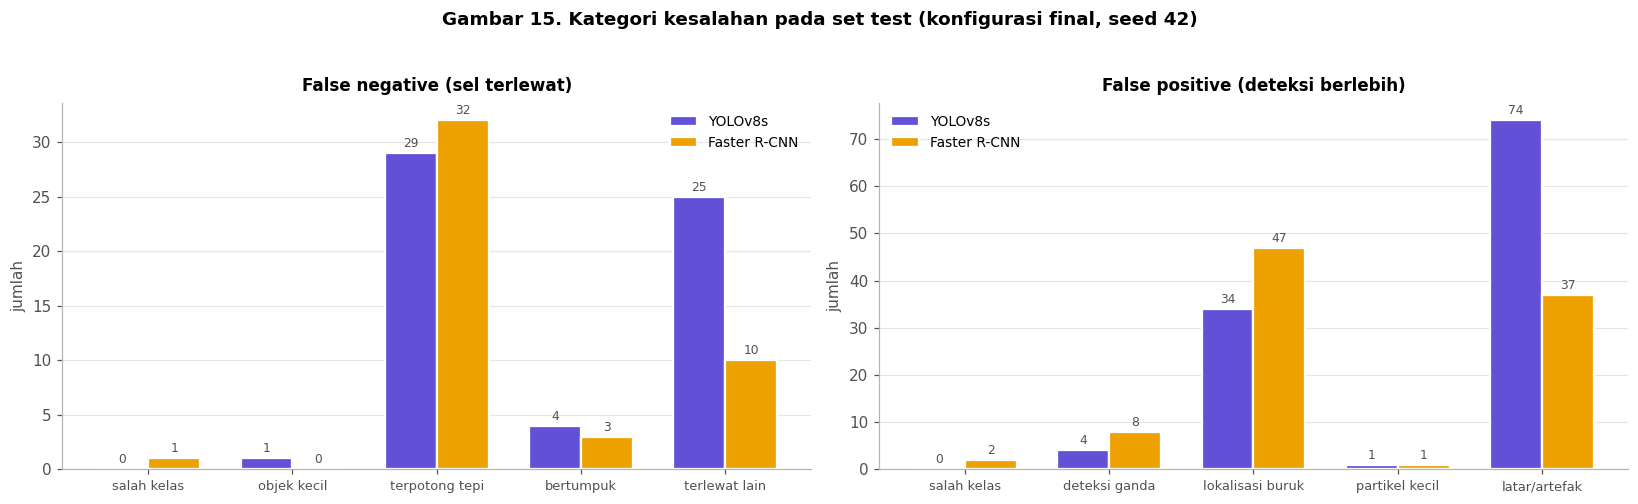

In [20]:
# Gambar 15 · frekuensi kategori kesalahan
if MATCH:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
    for ax, (jenis, cats) in zip(axes, [("FN", FN_CATS), ("FP", FP_CATS)]):
        w = 0.36
        for i, g in enumerate(MATCH):
            e = MATCH[g][MATCH[g].jenis == jenis].kategori.value_counts().reindex(cats, fill_value=0)
            bars = ax.bar(np.arange(len(cats)) + (i - 0.5) * w, e.values, w, color=MODEL_COLORS[g], label=g, **BAR)
            label_bars(ax, bars, "{:.0f}", fontsize=8)
        ax.set_xticks(range(len(cats)), cats, fontsize=8.5)
        ax.set_title("False negative (sel terlewat)" if jenis == "FN" else "False positive (deteksi berlebih)")
        ax.set_ylabel("jumlah"); ax.legend()
    fig.suptitle(f"Gambar 15. Kategori kesalahan pada set {SPLIT_AN} (konfigurasi final, seed 42)", fontweight="semibold", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig15_kategori_kesalahan.png"); plt.show()

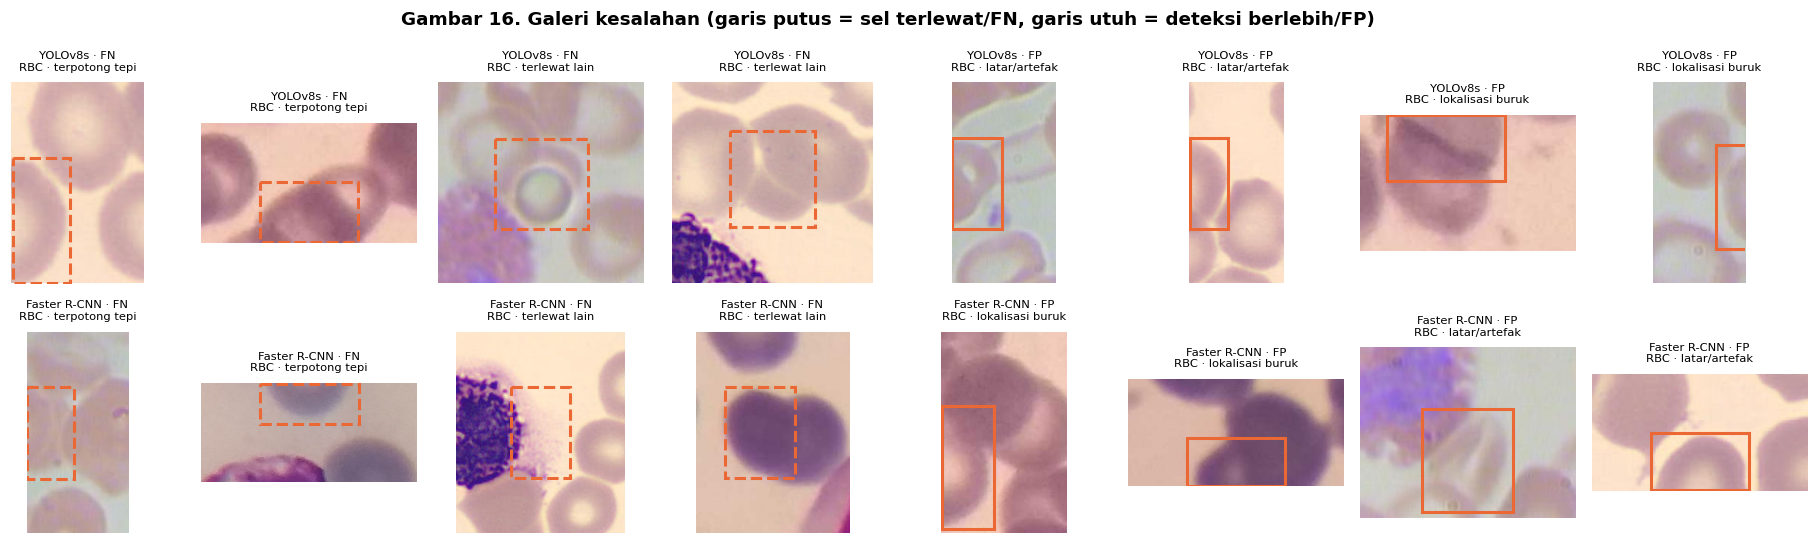

In [21]:
# Gambar 16 · galeri kesalahan: tiap model 4 FN + 4 FP dari kategori terbanyak (≥ 8 contoh per model)
from PIL import Image
rows_g = []
for g, m in MATCH.items():
    for jenis in ["FN", "FP"]:
        e = m[m.jenis == jenis]
        picked = []
        for cat in e.kategori.value_counts().index:              # sebar contoh ke beberapa kategori
            picked += e[e.kategori == cat].sample(min(2, (e.kategori == cat).sum()), random_state=SEED).to_dict("records")
        rows_g += [dict(model=g, **x) for x in picked[:4]]
if rows_g:
    n = len(rows_g)
    fig, axes = plt.subplots(int(np.ceil(n / 8)), 8, figsize=(17, 2.5 * np.ceil(n / 8)))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, x in zip(np.ravel(axes), rows_g):
        im = Image.open(DATA_ROOT / "images" / SPLIT_AN / imgs_an[x["image_id"]]["file_name"]).convert("RGB")
        bx, by, bw, bh = x["bbox"]
        pad = max(bw, bh) * 0.6
        ax.imshow(im.crop((max(0, bx - pad), max(0, by - pad), min(im.width, bx + bw + pad), min(im.height, by + bh + pad))))
        ax.add_patch(plt.Rectangle((min(pad, bx), min(pad, by)), bw, bh, fill=False, lw=2,
                                   ec=CLASS_COLORS[x["kelas"]], ls="-" if x["jenis"] == "FP" else "--"))
        ax.set_title(f"{x['model']} · {x['jenis']}\n{x['kelas']} · {x['kategori']}", fontsize=7.5, fontweight="normal")
    fig.suptitle("Gambar 16. Galeri kesalahan (garis putus = sel terlewat/FN, garis utuh = deteksi berlebih/FP)", fontweight="semibold")
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig16_galeri_kesalahan.png"); plt.show()

### 5.2 Interpretabilitas EigenCAM — Tsabita
EigenCAM (bebas gradien, sejenis Grad-CAM) dipakai untuk **kedua** model pada lapisan ber-stride 8 (YOLOv8s: neck P3;
Faster R-CNN: FPN P3) agar adil. Dipilih **4 citra benar** (galat hitung 0) dan **4 citra salah** (galat absolut
terbesar) per model dari 5.1. Porsi energi peta panas di dalam kotak tiap kelas vs latar dihitung supaya tafsiran
berbasis angka. **Dijalankan:** otomatis sekali; hasil (tabel energi + gambar) disimpan ke Drive dan ditampilkan ulang
pada sesi berikutnya (pemilik: Tsabita). **Cara membaca:** energi besar di latar pada kasus salah →
model terganggu artefak/latar; energi kecil di kotak platelet → platelet kurang diperhatikan.

In [22]:
XAI_CSV = EVAL_DIR / f"xai_energi_{SPLIT_AN}.csv"
xai_figs = [FIG_DIR / f"fig{k}_eigencam_{r}.png" for k, r in enumerate(AN_RUNS.values(), start=17)]
if MATCH and not (XAI_CSV.exists() and all(f.exists() for f in xai_figs)) and boleh("XAI"):
    from src.xai import yolo_eigencam, frcnn_eigencam, energy_share, overlay
    from src import frcnn
    gt_by_img = {}
    for a in gt_an["annotations"]:
        gt_by_img.setdefault(a["image_id"], {c: [] for c in CLASSES})[CLASSES[a["category_id"] - 1]].append(a["bbox"])
    XAI_ROWS = []
    for g, r in AN_RUNS.items():
        m = MATCH[g]
        per = m.groupby(["image_id", "jenis"]).size().unstack(fill_value=0).reindex(columns=["TP", "FP", "FN"], fill_value=0)
        per["err"] = per.FP + per.FN
        per["f1"] = 2 * per.TP / (2 * per.TP + per.FP + per.FN)
        benar = per[per.err == 0].sort_values("TP", ascending=False).head(4).index.tolist()
        if len(benar) < 4:
            benar += per.drop(benar).sort_values("f1", ascending=False).head(4 - len(benar)).index.tolist()
        salah = per.sort_values("err", ascending=False).head(4).index.tolist()
        cfg = load_config(r)
        model = frcnn.load_best(cfg, RUNS_DIR / r, device="cuda") if g == "Faster R-CNN" else None
        for kasus, ids in [("benar", benar), ("salah", salah)]:
            for i in ids:
                path = DATA_ROOT / "images" / SPLIT_AN / imgs_an[i]["file_name"]
                cam = yolo_eigencam(RUNS_DIR / r / "weights" / "best.pt", path, cfg["imgsz"]) if model is None else frcnn_eigencam(model, path)
                es = energy_share(cam, gt_by_img.get(i, {c: [] for c in CLASSES}))
                XAI_ROWS.append(dict(model=g, run=r, kasus=kasus, image_id=i, cam=cam, path=path,
                                     FP=int(per.loc[i, "FP"]), FN=int(per.loc[i, "FN"]), **es))
        del model
        from src.xai import clear_cache
        clear_cache()                                      # lepas model YOLO yang di-cache EigenCAM
        P.free_gpu(verbose=False)
    xai_df = pd.DataFrame([{k: v for k, v in x.items() if k not in ("cam", "path")} for x in XAI_ROWS])
    xai_df.to_csv(EVAL_DIR / f"xai_energi_{SPLIT_AN}.csv", index=False)
    print("=== Porsi energi EigenCAM (rerata) di dalam kotak tiap kelas vs latar ===")
    display(xai_df.groupby(["model", "kasus"])[CLASSES + ["latar", "luas_latar"]].mean().round(3))

    for k, g in enumerate(AN_RUNS, start=17):              # Gambar 17–18
        rows_x = [x for x in XAI_ROWS if x["model"] == g]
        fig, axes = plt.subplots(2, 4, figsize=(16, 8.2))
        for ax, x in zip(np.ravel(axes), rows_x):
            ax.imshow(overlay(x["path"], x["cam"])); ax.axis("off")
            for c in CLASSES:
                for bx, by, bw, bh in gt_by_img.get(x["image_id"], {}).get(c, []):
                    ax.add_patch(plt.Rectangle((bx, by), bw, bh, fill=False, lw=1, ec="white", alpha=0.7))
            ax.set_title(f"{x['kasus']} · FP {x['FP']} · FN {x['FN']}\nenergi: WBC {x['WBC']:.2f} · RBC {x['RBC']:.2f} · "
                         f"PLT {x['Platelets']:.2f} · latar {x['latar']:.2f}", fontsize=8, fontweight="normal")
        fig.suptitle(f"Gambar {k}. EigenCAM {g} ({AN_RUNS[g]}, set {SPLIT_AN}): atas = benar, bawah = salah; kotak putih = ground truth",
                     fontweight="semibold")
        fig.tight_layout(); fig.savefig(FIG_DIR / f"fig{k}_eigencam_{AN_RUNS[g]}.png"); plt.show()
elif XAI_CSV.exists():
    from IPython.display import Image as IPImage
    print(f"SKIP (sudah selesai): EigenCAM · memakai hasil tersimpan {XAI_CSV.name}")
    xai_df = pd.read_csv(XAI_CSV)
    print("=== Porsi energi EigenCAM (rerata) di dalam kotak tiap kelas vs latar ===")
    display(xai_df.groupby(["model", "kasus"])[CLASSES + ["latar", "luas_latar"]].mean().round(3))
    for f in xai_figs:
        if f.exists():
            print("===", f.name, "==="); display(IPImage(filename=str(f)))
else:
    print("TUNDA: EigenCAM · " + ("menunggu hasil 5.1" if not MATCH else "GPU tidak aktif" if not GPU_OK else "milik Tsabita"))

Output hidden; open in https://colab.research.google.com to view.

**Cara menulis di laporan (Diskusi):** untuk tiap kategori kesalahan terbanyak, kaitkan dengan karakteristik data
dari audit M2 (platelet kecil, sel terpotong tepi, perbedaan pewarnaan antar sumber). Tafsirkan EigenCAM dengan angka
porsi energi, lalu tulis satu paragraf keterbatasan dan risiko bila model dipakai di laboratorium klinis.

## 6. Ringkasan: kurva pelatihan, jawaban hipotesis, total jam GPU & arsip hasil — Bersama
Aturan keputusan ditetapkan di proposal M1 sebelum hasil terlihat. Hasil ablasi satu seed disebut **indikatif**.

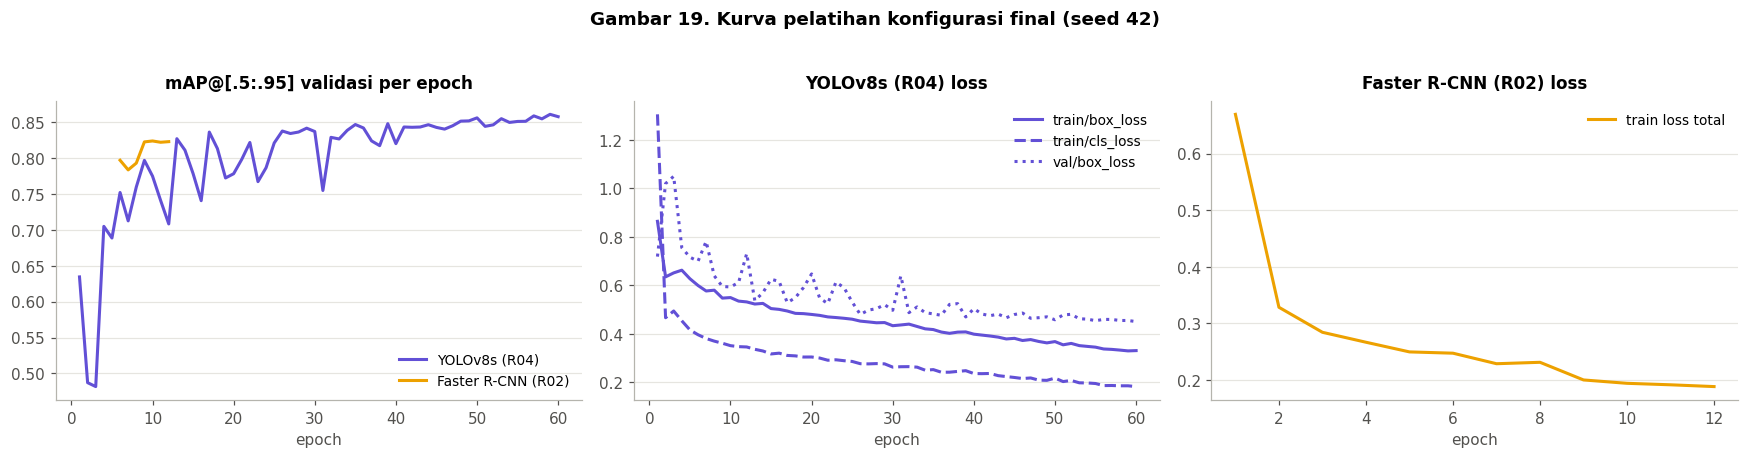

In [23]:
# Gambar 19 · kurva pelatihan konfigurasi final seed 42 (memantau konvergensi; angka laporan tetap dari pycocotools)
curves = {}
for kind, r in BEST.items():
    f = RUNS_DIR / r / ("results.csv" if kind == "yolo" else "history.csv")
    if f.exists():
        d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]
        curves[kind] = (r, d)
if curves:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for kind, (r, d) in curves.items():
        g = "YOLOv8s" if kind == "yolo" else "Faster R-CNN"
        y = d["metrics/mAP50-95(B)"] if kind == "yolo" else d["val_mAP50_95"]
        axes[0].plot(d["epoch"], y, lw=2, color=MODEL_COLORS[g], label=f"{g} ({r})")
    axes[0].set_title("mAP@[.5:.95] validasi per epoch"); axes[0].set_xlabel("epoch"); axes[0].legend()
    if "yolo" in curves:
        r, d = curves["yolo"]
        for c, ls in [("train/box_loss", "-"), ("train/cls_loss", "--"), ("val/box_loss", ":")]:
            axes[1].plot(d["epoch"], d[c], lw=2, ls=ls, color=MODEL_COLORS["YOLOv8s"], label=c)
        axes[1].set_title(f"YOLOv8s ({r}) loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    if "frcnn" in curves:
        r, d = curves["frcnn"]
        axes[2].plot(d["epoch"], d["train_loss"], lw=2, color=MODEL_COLORS["Faster R-CNN"], label="train loss total")
        axes[2].set_title(f"Faster R-CNN ({r}) loss"); axes[2].set_xlabel("epoch"); axes[2].legend()
    fig.suptitle("Gambar 19. Kurva pelatihan konfigurasi final (seed 42)", fontweight="semibold", y=1.03)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig19_kurva_pelatihan.png"); plt.show()

In [24]:
# Jawaban hipotesis H1–H3 (aturan dari proposal M1)
hasil = []
if len(corr_val):
    rr = corr_val[(corr_val.kelompok == "semua run") & (corr_val.kelas == "RBC") & (corr_val.x == "mAP50_95")]
    if len(rr):
        rho = rr.spearman_rho.iloc[0]
        hasil.append(dict(hipotesis="H1", uji=f"Spearman ρ mAP@[.5:.95] vs MAE RBC antar run = {rho:.2f} (n = {len(val)}); lemah bila |ρ| < 0,5",
                          keputusan="didukung" if abs(rho) < 0.5 else "tidak didukung"))
if len(nms_df):
    for g, d in nms_df.groupby("model"):
        rng_ = d.MAE_RBC.max() - d.MAE_RBC.min()
        hasil.append(dict(hipotesis=f"H2 ({g})", uji=f"rentang MAE RBC pada NMS 0,45–0,75 = {rng_:.3f} sel/citra (< 0,10 → NMS bukan penyebab dominan)",
                          keputusan="didukung" if rng_ < 0.10 else "tidak didukung"))
if all(r in val.index for r in ["R01", "R04"]):
    a, b = float(val.loc["R01", "MAE_Platelets"]), float(val.loc["R04", "MAE_Platelets"])
    turun = (a - b) / a if a > 0 else float("nan")
    hasil.append(dict(hipotesis="H3 (indikatif, 1 seed)", uji=f"MAE platelet 640 → 832: {a:.3f} → {b:.3f} (turun {turun:.0%}; target ≥ 10%)",
                      keputusan="didukung" if turun >= 0.10 else "tidak didukung"))
if TEST_OK:
    mt = num_test.xs("mean", level=1)
    tertinggi = all(mt.loc[g, "MAPE_Platelets"] >= max(mt.loc[g, "MAPE_WBC"], mt.loc[g, "MAPE_RBC"]) for g in GROUPS)
    hasil.append(dict(hipotesis="H3 (uji, 3 seed)", uji="MAPE platelet tertinggi di kedua model: " +
                      ", ".join(f"{g} {mt.loc[g, 'MAPE_Platelets']:.1f}%" for g in GROUPS), keputusan="didukung" if tertinggi else "tidak didukung"))
pd.set_option("display.max_colwidth", 200)
print("=== JAWABAN HIPOTESIS ===")
display(pd.DataFrame(hasil) if hasil else "Belum ada cukup hasil untuk menguji hipotesis.")

=== JAWABAN HIPOTESIS ===


,hipotesis,uji,keputusan
0,H1,"Spearman ρ mAP@[.5:.95] vs MAE RBC antar run = 0.52 (n = 14); lemah bila |ρ| < 0,5",tidak didukung
1,H2 (Faster R-CNN),"rentang MAE RBC pada NMS 0,45–0,75 = 0.333 sel/citra (< 0,10 → NMS bukan penyebab dominan)",tidak didukung
2,H2 (YOLOv8s),"rentang MAE RBC pada NMS 0,45–0,75 = 0.004 sel/citra (< 0,10 → NMS bukan penyebab dominan)",didukung
3,"H3 (indikatif, 1 seed)",MAE platelet 640 → 832: 0.075 → 0.071 (turun 5%; target ≥ 10%),tidak didukung
4,"H3 (uji, 3 seed)","MAPE platelet tertinggi di kedua model: YOLOv8s 11.8%, Faster R-CNN 5.9%",tidak didukung


In [2]:
# Arsip ringkas hasil M3 (berdiri sendiri: aman dijalankan walau sesi Colab ter-restart)
import os, sys, zipfile
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/UAS")
assert (PROJECT_ROOT / "src" / "pipeline.py").exists(), "Folder UAS tidak ditemukan, cek path-nya"
os.chdir(PROJECT_ROOT); sys.path.insert(0, str(PROJECT_ROOT))
from src.exp_log import read_log
OUTPUT_DIR = PROJECT_ROOT / "outputs"

log = read_log()
print(f"Total waktu GPU tim: {log.gpu_minutes.fillna(0).astype(float).sum() / 60:.1f} jam "
      f"({(log.status == 'done').sum()} run/varian selesai, {(log.status == 'failed').sum()} gagal tercatat)")
display(log.drop(columns=["date"]).fillna("–"))

bundle = OUTPUT_DIR / "m3_results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ["outputs/figures", "outputs/eval", "outputs/eda", "outputs/leakage", "experiments", "configs", "splits"]:
        p = PROJECT_ROOT / folder
        for f in sorted(p.rglob("*")) if p.exists() else []:
            if not f.is_file() or f.suffix.lower() in (".gsheet", ".gdoc", ".gslides", ".gdraw"):
                continue                     # pintasan Google Sheets/Docs tidak bisa dimasukkan ke zip
            try:
                zf.write(f, f.relative_to(PROJECT_ROOT))
            except OSError as e:
                print("dilewati:", f.relative_to(PROJECT_ROOT), f"({e.strerror})")
print(f"Selesai! Arsip ringkas M3: {bundle} ({bundle.stat().st_size / 1024**2:.1f} MB)")

Mounted at /content/drive
Total waktu GPU tim: 3.1 jam (14 run/varian selesai, 0 gagal tercatat)


,run_id,owner,model,factor,value,seed,status,gpu,gpu_minutes,val_mAP50,val_mAP50_95,val_AP_small,val_MAE_WBC,val_MAE_RBC,val_MAE_Platelets,notes
0,R01,Tsabita,yolov8s,baseline,imgsz 640,42,done,Tesla T4,17.7,0.9715,0.8478,0.7274,0.008,0.960,0.075,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
1,R01-nms0.45,Putri,yolov8s,A2 NMS IoU,R01 · NMS IoU 0.45,42,done,Tesla T4,0.2,0.9719,0.8472,0.7285,0.008,0.964,0.075,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
2,R01-nms0.60,Putri,yolov8s,A2 NMS IoU,R01 · NMS IoU 0.60,42,done,Tesla T4,0.1,0.9718,0.8476,0.7283,0.008,0.964,0.075,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
3,R01-nms0.75,Putri,yolov8s,A2 NMS IoU,R01 · NMS IoU 0.75,42,done,Tesla T4,0.1,0.9712,0.8482,0.7263,0.008,0.960,0.075,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
4,R02,Putri,fasterrcnn_resnet50_fpn,baseline,"anchor default, fine-tune penuh",42,done,Tesla T4,25.4,0.9815,0.8242,0.7259,0.012,0.679,0.048,"tau={'Platelets': 0.9, 'RBC': 0.7, 'WBC': 0.3}..."
5,R02-nms0.45,Putri,fasterrcnn_resnet50_fpn,A2 NMS IoU,R02 · NMS IoU 0.45,42,done,Tesla T4,0.4,0.9816,0.8245,0.7260,0.012,0.679,0.048,"tau={'Platelets': 0.9, 'RBC': 0.7, 'WBC': 0.15..."
6,R02-nms0.60,Putri,fasterrcnn_resnet50_fpn,A2 NMS IoU,R02 · NMS IoU 0.60,42,done,Tesla T4,0.3,0.9807,0.8243,0.7269,0.012,0.794,0.048,"tau={'Platelets': 0.9, 'RBC': 0.8, 'WBC': 0.35..."
7,R02-nms0.75,Putri,fasterrcnn_resnet50_fpn,A2 NMS IoU,R02 · NMS IoU 0.75,42,done,Tesla T4,0.3,0.9769,0.8245,0.7263,0.012,1.012,0.048,"tau={'Platelets': 0.9, 'RBC': 0.85, 'WBC': 0.5..."
8,R04,Tsabita,yolov8s,A1 resolusi,imgsz 832,42,done,Tesla T4,24.4,0.9756,0.8488,0.7321,0.008,0.944,0.071,"tau={'Platelets': 0.75, 'RBC': 0.7, 'WBC': 0.7..."
9,R06,Putri,fasterrcnn_resnet50_fpn,strategi fine-tuning,backbone beku,42,done,Tesla T4,17.3,0.9819,0.7857,0.6872,0.024,0.766,0.056,"tau={'Platelets': 0.8, 'RBC': 0.8, 'WBC': 0.8}..."


Selesai! Arsip ringkas M3: /content/drive/MyDrive/Colab Notebooks/UAS/outputs/m3_results_bundle.zip (12.7 MB)
